# GNN + MCTS Parameter Sweep

Benchmark different MCTS settings on the same validation scenarios.

The final method is fixed:

- GNN-guided MCTS
- STOP disabled during search
- No stop + Pareto terminal selection
- stored Teacher baseline for comparison

Each MCTS setting is saved to its own CSV file.

## 1. Settings

In [2]:
from pathlib import Path

PROJECT_DIR = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "pyproject.toml").exists()
)

RAW_DIR = PROJECT_DIR / "data/paper/gridfm_generated/case118_17k/raw"
DATASET_ROOT = PROJECT_DIR / "data/paper/dataset/case118_17k_v2"
VAL_CSV = DATASET_ROOT / "examples_val.csv"
CHECKPOINT = PROJECT_DIR / "data/paper/models/case118_17k_v2/graph_policy_value_net.pt"

RESULTS_DIR = PROJECT_DIR / "data/paper/analysis/mcts_parameter_analysis"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

#None = full validation dataset
N_SCENARIOS = None
SCENARIO_SEED = 42
SEED = 42
RESET_RESULTS = False

MCTS_SETTINGS = [
    {
        "name": "sim_25",
        "num_simulations": 25,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
    {
        "name": "sim_50",
        "num_simulations": 50,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
    {
        "name": "sim_100",
        "num_simulations": 100,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
    {
        "name": "sim_200",
        "num_simulations": 200,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
    {
        "name": "sim_300",
        "num_simulations": 300,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
    {
        "name": "sim_400",
        "num_simulations": 400,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
    {
        "name": "sim_500",
        "num_simulations": 500,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
    {
        "name": "sim_2000",
        "num_simulations": 2000,
        "max_depth": None,
        "top_k_actions": 30,
        "widening_coefficient": 2.0,
        "widening_exponent": 0.5,
        "exploration_quota": 2,
        "gamma": 1.0,
        "c_puct": 2.0,
        "prior_exponent": 0.5,
        "pareto_per_switch_count": 5,
    },
]

ANALYSIS_SETTING = "sim_100"

Change `N_SCENARIOS` to control the benchmark size.

`max_depth = None` means that the MCTS depth matches the Teacher depth for each difficulty class.

When you change parameters, give the setting a new unique `name`.

## 2. Imports

In [3]:
import json
import subprocess
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from grid_topology_ai.actions import GridFMActionSpace
from grid_topology_ai.data import GridFMAdapter
from grid_topology_ai.environment import TopologySwitchingEnv
from grid_topology_ai.evaluator import NeuralPolicyValueEvaluator
from grid_topology_ai.physics.objective import assess_physical_state
from grid_topology_ai.physics.redispatch import run_minimal_ac_redispatch
from grid_topology_ai.physics.utility import GridFMReward, state_security_penalty
from grid_topology_ai.power_flow.backend import GridFMPowerFlowBackend
from grid_topology_ai.search.mcts import MCTSConfig, MCTSPlanner
from grid_topology_ai.search.teacher import (
    ImpactBeamSearchNode,
    _TERMINAL_REDISPATCH_ABSOLUTE_EPSILON_MW,
    _TERMINAL_REDISPATCH_RELATIVE_EPSILON,
    _select_terminal_candidate,
    _terminal_candidate,
    switch_count,
    update_top_j_candidate_archive,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

git_head = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_DIR,
    text=True,
).strip()

print("Git:", git_head)
print("Torch:", torch.__version__)

Git: c672c8b167e8948f7790cd0ff62c0596f2f760b2
Torch: 2.5.1+cu124


## 3. Teacher settings and scenarios

In [4]:
teacher_tasks = {}

for difficulty in ["simple", "medium", "hard"]:
    path = DATASET_ROOT / "val" / difficulty / "teacher_checkpoint_config.json"
    teacher_tasks[difficulty] = json.loads(
        path.read_text(encoding="utf-8")
    )["task_config"]

teacher_settings = pd.DataFrame([
    {
        "difficulty": difficulty,
        "depth": task["depth"],
        "max_steps": task["max_steps"],
        "beam_width": task["beam_width"],
        "candidate_pool": task["candidate_pool"],
        "top_k": task["top_k"],
        "redispatch_candidates": task["redispatch_candidates_per_switch_count"],
    }
    for difficulty, task in teacher_tasks.items()
])

display(teacher_settings)

,difficulty,depth,max_steps,beam_width,candidate_pool,top_k,redispatch_candidates
0,simple,4,5,10,60,30,8
1,medium,5,5,20,160,70,8
2,hard,6,6,30,220,100,8


In [5]:
scenario_table = pd.read_csv(
    VAL_CSV,
    usecols=["scenario_id", "difficulty_class", "state_path"],
).drop_duplicates("scenario_id")

scenario_pool = (
    scenario_table
    .sample(frac=1, random_state=SCENARIO_SEED)
    .reset_index(drop=True)
)

if N_SCENARIOS is None:
    scenarios = scenario_pool.copy()
else:
    scenarios = scenario_pool.head(N_SCENARIOS).copy()

scenarios = scenarios.sort_values(
    ["difficulty_class", "scenario_id"]
).reset_index(drop=True)

print("Scenarios:", len(scenarios))
display(scenarios.groupby("difficulty_class").size())
display(scenarios.head(10))

Scenarios: 2000


difficulty_class
hard       500
medium    1000
simple     500
dtype: int64

,state_path,scenario_id,difficulty_class
0,data/paper/dataset/case118_17k_v2/val/hard/sta...,12754,hard
1,data/paper/dataset/case118_17k_v2/val/hard/sta...,12760,hard
2,data/paper/dataset/case118_17k_v2/val/hard/sta...,12778,hard
3,data/paper/dataset/case118_17k_v2/val/hard/sta...,12779,hard
4,data/paper/dataset/case118_17k_v2/val/hard/sta...,12794,hard
5,data/paper/dataset/case118_17k_v2/val/hard/sta...,12810,hard
6,data/paper/dataset/case118_17k_v2/val/hard/sta...,12813,hard
7,data/paper/dataset/case118_17k_v2/val/hard/sta...,12815,hard
8,data/paper/dataset/case118_17k_v2/val/hard/sta...,12827,hard
9,data/paper/dataset/case118_17k_v2/val/hard/sta...,12833,hard


## 4. Teacher baseline

In [6]:
teacher_baseline = {}

for row in scenarios.itertuples():
    path = PROJECT_DIR / Path(row.state_path)

    with np.load(path, allow_pickle=False) as data:
        meta = json.loads(
            np.asarray(data["metadata_json"]).item()
        )

    actions = [int(x) for x in meta["best_sequence_action_ids"]]
    branches = [
        None if x is None else int(x)
        for x in meta["best_sequence_branch_ids"]
    ]

    solved = bool(meta["episode_solved"])
    rd_validated = bool(meta["redispatch_validated"])
    terminal_validated = solved or rd_validated

    redispatch_l1 = (
        0.0
        if solved
        else (
            float(meta["redispatch_l1_mw"])
            if rd_validated
            else np.nan
        )
    )

    teacher_baseline[int(row.scenario_id)] = {
        "scenario_id": int(row.scenario_id),
        "difficulty": row.difficulty_class,
        "variant": "teacher",
        "J0": float(meta["initial_safety"]),
        "Jfinal": float(meta["replay_final_safety"]),
        "initial_redispatch_validated": bool(
            meta["initial_redispatch_validated"]
        ),
        "initial_redispatch_l1_mw": (
            float(meta["initial_redispatch_l1_mw"])
            if meta["initial_redispatch_validated"]
            else np.nan
        ),
        "actions": str(actions),
        "branches": str(branches),
        "switches": int(meta["teacher_selected_switch_count"]),
        "depth": len(actions),
        "stop_selected": bool(actions and actions[-1] == 0),
        "solved": solved,
        "hard_overloads": int(meta["replay_final_num_hard_overloaded"]),
        "overloads": int(meta["replay_final_num_overloaded"]),
        "max_loading": float(meta["replay_final_max_loading_percent"]),
        "redispatch_attempted": bool(meta["redispatch_attempted"]),
        "redispatch_validated": terminal_validated,
        "redispatch_l1_mw": redispatch_l1,
        "evaluated_topology_actions": int(meta["evaluated_actions"]),
        "tree_nodes": np.nan,
        "selection_candidates": int(
            meta["teacher_redispatch_candidate_count"]
        ),
        "terminal_candidates": int(
            meta["teacher_terminal_candidate_count"]
        ),
        "pareto_front_size": int(
            meta["teacher_terminal_pareto_front_size"]
        ),
        "initial_time_s": np.nan,
        "search_time_s": np.nan,
        "selection_time_s": np.nan,
        "runtime_s": np.nan,
        "search_runpf_calls": np.nan,
        "search_pf_cache_misses": np.nan,
        "search_pf_cache_hits": np.nan,
    }

print("Teacher baseline:", len(teacher_baseline))

Teacher baseline: 2000


## 5. Model and environment

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"

evaluator = NeuralPolicyValueEvaluator(
    CHECKPOINT,
    device=device,
    enable_cache=True,
)

physics = evaluator.physics_config
action_config = evaluator.topology_action_config

adapter = GridFMAdapter(
    RAW_DIR,
    physics_config=physics,
)

print("Device:", device)
print("Physics:", physics)
print("Actions:", action_config)

Device: cuda
Physics: PhysicsConfig(base_mva=100.0, pf_alg=1, pf_tolerance=1e-08, max_iterations=30, q_limit_policy=<QLimitPolicy.ENFORCE: 'enforce'>, island_policy=<IslandPolicy.REJECT: 'reject'>, zero_rate_a_policy=<ZeroRateAPolicy.UNLIMITED: 'unlimited'>, overload_limit_percent=100.0, hard_overload_limit_percent=120.0, thermal_tolerance_percent=1e-06, voltage_tolerance_pu=1e-06, generator_p_tolerance_mw=1e-06, generator_q_tolerance_mvar=1e-06, angle_tolerance_degrees=1e-06)
Actions: ActionSpaceConfig(require_connected_after_switch=True, min_loading_for_switch_percent=0.0, closeable_branch_ids=(), enable_cache=True)


In [8]:
def new_backend():
    return GridFMPowerFlowBackend(
        adapter=adapter,
        physics_config=physics,
        enable_cache=True,
    )


def new_action_space():
    return GridFMActionSpace(
        require_connected_after_switch=action_config.require_connected_after_switch,
        min_loading_for_switch_percent=action_config.min_loading_for_switch_percent,
        closeable_branch_ids=action_config.closeable_branch_ids,
        enable_cache=True,
    )


def new_env(max_steps, backend=None):
    backend = backend or new_backend()

    return TopologySwitchingEnv(
        adapter=adapter,
        backend=backend,
        action_space=new_action_space(),
        reward_fn=GridFMReward(
            physics_config=physics,
            discount_factor=1.0,
        ),
        max_steps=int(max_steps),
    )


def perf(backend):
    info = backend.performance_info()

    return {
        "runpf_calls": int(info["stock_runpf_calls"]),
        "pf_cache_misses": int(info["misses"]),
        "pf_cache_hits": int(info["hits"]),
    }

## 6. No stop + Pareto selection

In [9]:
def candidate_from_mcts_node(node, action_ids, branch_ids):
    state = node.env.current_state

    return ImpactBeamSearchNode(
        env=node.env,
        action_ids=list(action_ids),
        branch_ids=list(branch_ids),
        discounted_score=float(node.mean_value),
        safety_score=float(
            state_security_penalty(
                state,
                physics_config=physics,
            )
        ),
        max_loading_percent=float(state.metrics["max_loading_percent"]),
        num_overloaded=int(state.metrics["num_overloaded_branches"]),
        num_hard_overloaded=int(state.metrics["num_hard_overloaded_branches"]),
        depth=len(action_ids),
        done=bool(node.done),
        solved=bool(node.solved),
        termination_reason=node.env.termination_reason,
    )


def all_mcts_candidates(result):
    rows = []

    def walk(node, action_ids, branch_ids):
        rows.append(
            candidate_from_mcts_node(
                node,
                action_ids,
                branch_ids,
            )
        )

        for action_id, child in node.children.items():
            action = child.action_from_parent

            walk(
                child,
                [*action_ids, int(action_id)],
                [*branch_ids, action.branch_id],
            )

    walk(result.root, [], [])

    return rows


def best_j_candidate_from_nodes(nodes):
    return min(
        nodes,
        key=lambda node: (
            node.safety_score,
            switch_count(node),
            tuple(node.action_ids),
        ),
    )

In [10]:
def redispatch_key(state):
    key = [
        np.asarray(
            state.branch_status,
            dtype=np.int8,
        ).tobytes()
    ]

    generator_p = getattr(
        state,
        "generator_p_mw",
        None,
    )

    if generator_p is not None:
        key.append(
            np.asarray(
                generator_p,
                dtype=np.float64,
            ).tobytes()
        )

    return tuple(key)


def cached_redispatch(backend, state, cache):
    key = redispatch_key(state)

    if key not in cache:
        cache[key] = run_minimal_ac_redispatch(
            backend,
            state,
        )

    return cache[key]


def evaluate_final_node(
    node,
    redispatch_result=None,
    redispatch_backend=None,
    redispatch_cache=None,
):
    state = node.env.current_state
    assessment = assess_physical_state(state.metrics)

    if assessment.physically_secure:
        validated = True
        redispatch_l1 = 0.0
        redispatch_attempted = False
    else:
        redispatch_attempted = True

        if redispatch_result is None:
            redispatch_result = cached_redispatch(
                redispatch_backend,
                state,
                redispatch_cache,
            )

        validated = bool(redispatch_result.validated)
        redispatch_l1 = (
            float(redispatch_result.redispatch_l1_mw)
            if validated
            else np.nan
        )

    return {
        "actions": str([int(x) for x in node.action_ids]),
        "branches": str([
            None if x is None else int(x)
            for x in node.branch_ids
        ]),
        "switches": int(switch_count(node)),
        "depth": int(len(node.action_ids)),
        "stop_selected": False,
        "Jfinal": float(
            state_security_penalty(
                state,
                physics_config=physics,
            )
        ),
        "solved": bool(assessment.physically_secure),
        "hard_overloads": int(
            state.metrics["num_hard_overloaded_branches"]
        ),
        "overloads": int(
            state.metrics["num_overloaded_branches"]
        ),
        "max_loading": float(
            state.metrics["max_loading_percent"]
        ),
        "redispatch_attempted": redispatch_attempted,
        "redispatch_validated": validated,
        "redispatch_l1_mw": redispatch_l1,
    }


def no_stop_pareto_candidate(
    nodes,
    redispatch_backend,
    redispatch_cache,
    per_switch_count,
):
    archive = update_top_j_candidate_archive(
        {},
        nodes,
        per_switch_count=per_switch_count,
    )

    candidates = [
        node
        for num_switches in sorted(archive)
        for node in archive[num_switches]
    ]

    solved_switch_counts = [
        switch_count(node)
        for node in candidates
        if assess_physical_state(
            node.env.current_state.metrics
        ).physically_secure
    ]

    if solved_switch_counts:
        max_switches = min(solved_switch_counts)
        candidates = [
            node
            for node in candidates
            if switch_count(node) <= max_switches
        ]

    terminal = []

    for node in candidates:
        state = node.env.current_state
        assessment = assess_physical_state(state.metrics)

        if assessment.physically_secure:
            candidate = _terminal_candidate(node)
        else:
            rd = cached_redispatch(
                redispatch_backend,
                state,
                redispatch_cache,
            )

            candidate = _terminal_candidate(
                node,
                redispatch_result=rd,
            )

        if candidate is not None:
            terminal.append(candidate)

    if not terminal:
        return (
            best_j_candidate_from_nodes(nodes),
            None,
            len(candidates),
            0,
            0,
        )

    selected, front, pool = _select_terminal_candidate(
        terminal,
        relative_epsilon=_TERMINAL_REDISPATCH_RELATIVE_EPSILON,
        absolute_epsilon_mw=_TERMINAL_REDISPATCH_ABSOLUTE_EPSILON_MW,
    )

    return (
        selected.node,
        selected.redispatch_result,
        len(candidates),
        len(terminal),
        len(front),
    )

## 7. MCTS search

In [11]:
def mcts_horizon(difficulty, setting):
    max_depth = setting["max_depth"]

    if max_depth is None:
        max_depth = teacher_tasks[difficulty]["depth"]

    max_steps = teacher_tasks[difficulty]["max_steps"]

    return int(max_depth), int(max_steps)


def run_mcts_search(scenario_id, difficulty, setting):
    depth, max_steps = mcts_horizon(
        difficulty,
        setting,
    )

    evaluator.clear_cache()
    env = new_env(max_steps=max_steps)

    total_started = time.perf_counter()
    env.reset(int(scenario_id))
    initial_time = time.perf_counter() - total_started

    config = MCTSConfig(
        num_simulations=setting["num_simulations"],
        max_depth=depth,
        top_k_actions=setting["top_k_actions"],
        widening_coefficient=setting["widening_coefficient"],
        widening_exponent=setting["widening_exponent"],
        exploration_quota=setting["exploration_quota"],
        gamma=setting["gamma"],
        c_puct=setting["c_puct"],
        prior_exponent=setting["prior_exponent"],
        include_stop_action=False,
        stop_policy="never",
        use_root_dirichlet_noise=False,
        random_seed=SEED + int(scenario_id),
    )

    planner = MCTSPlanner(
        config=config,
        evaluator=evaluator,
        physics_config=physics,
    )

    before = perf(env.backend)

    started = time.perf_counter()
    result = planner.search_from_env(env)
    search_time = time.perf_counter() - started

    after = perf(env.backend)

    return {
        "result": result,
        "backend": env.backend,
        "initial_time_s": initial_time,
        "search_time_s": search_time,
        "search_runpf_calls": after["runpf_calls"] - before["runpf_calls"],
        "search_pf_cache_misses": after["pf_cache_misses"] - before["pf_cache_misses"],
        "search_pf_cache_hits": after["pf_cache_hits"] - before["pf_cache_hits"],
    }

## 8. Benchmark

In [12]:
def make_mcts_row(
    scenario_id,
    difficulty,
    search,
    final,
    selection_time,
    tree_nodes,
    selection_candidates,
    terminal_candidates,
    pareto_front_size,
):
    initial_state = search["result"].root.env.current_state

    return {
        "scenario_id": int(scenario_id),
        "difficulty": difficulty,
        "variant": "gnn_mcts",
        "J0": float(
            state_security_penalty(
                initial_state,
                physics_config=physics,
            )
        ),
        "initial_redispatch_validated": np.nan,
        "initial_redispatch_l1_mw": np.nan,
        "initial_time_s": search["initial_time_s"],
        "search_time_s": search["search_time_s"],
        "selection_time_s": selection_time,
        "runtime_s": (
            search["initial_time_s"]
            + search["search_time_s"]
            + selection_time
        ),
        "search_runpf_calls": search["search_runpf_calls"],
        "search_pf_cache_misses": search["search_pf_cache_misses"],
        "search_pf_cache_hits": search["search_pf_cache_hits"],
        "evaluated_topology_actions": search["search_pf_cache_misses"],
        "tree_nodes": tree_nodes,
        "selection_candidates": selection_candidates,
        "terminal_candidates": terminal_candidates,
        "pareto_front_size": pareto_front_size,
        **final,
    }


def run_teacher(scenario_id):
    return dict(
        teacher_baseline[int(scenario_id)]
    )


def benchmark_scenario(
    scenario_id,
    difficulty,
    setting,
):
    teacher = run_teacher(scenario_id)

    search = run_mcts_search(
        scenario_id,
        difficulty,
        setting,
    )

    nodes = all_mcts_candidates(
        search["result"]
    )

    redispatch_backend = new_backend()
    redispatch_cache = {}

    started = time.perf_counter()

    (
        selected_node,
        selected_redispatch,
        archive_size,
        terminal_count,
        front_size,
    ) = no_stop_pareto_candidate(
        nodes,
        redispatch_backend,
        redispatch_cache,
        setting["pareto_per_switch_count"],
    )

    final = evaluate_final_node(
        selected_node,
        redispatch_result=selected_redispatch,
        redispatch_backend=redispatch_backend,
        redispatch_cache=redispatch_cache,
    )

    selection_time = time.perf_counter() - started

    mcts = make_mcts_row(
        scenario_id,
        difficulty,
        search,
        final,
        selection_time,
        len(nodes),
        archive_size,
        terminal_count,
        front_size,
    )

    mcts["initial_redispatch_l1_mw"] = teacher["initial_redispatch_l1_mw"]
    mcts["initial_redispatch_validated"] = teacher["initial_redispatch_validated"]

    return [
        teacher,
        mcts,
    ]

In [13]:
def make_results(rows, setting):
    frame = pd.DataFrame(rows)

    frame["delta_J"] = (
        frame["J0"]
        - frame["Jfinal"]
    )

    frame["relative_J_improvement"] = (
        frame["delta_J"]
        / frame["J0"]
    )

    frame["redispatch_reduction_mw"] = (
        frame["initial_redispatch_l1_mw"]
        - frame["redispatch_l1_mw"]
    )

    frame["setting"] = setting["name"]

    for key, value in setting.items():
        if key != "name":
            frame[key] = value

    frame["seed"] = SEED
    frame["scenario_seed"] = SCENARIO_SEED

    return frame


def run_setting(setting):
    path = RESULTS_DIR / f"{setting['name']}.csv"

    if RESET_RESULTS and path.exists():
        path.unlink()

    all_rows = []
    done_scenarios = set()

    if path.exists():
        old = pd.read_csv(path)

        selected_ids = set(
            scenarios["scenario_id"].astype(int)
        )

        old = old[
            old["scenario_id"].astype(int).isin(selected_ids)
        ]

        done_scenarios = set(
            old.groupby("scenario_id")
            .filter(lambda x: set(x["variant"]) == {"teacher", "gnn_mcts"})
            ["scenario_id"]
            .astype(int)
            .unique()
        )

        old = old[
            old["scenario_id"].astype(int).isin(done_scenarios)
        ]

        all_rows = old.to_dict("records")

        print(
            f"{setting['name']}: resume from "
            f"{len(done_scenarios)} scenarios"
        )
    else:
        print(
            f"{setting['name']}: starting new benchmark"
        )

    started = time.perf_counter()

    for row in scenarios.itertuples():
        scenario_id = int(row.scenario_id)
        difficulty = row.difficulty_class

        if scenario_id in done_scenarios:
            continue

        scenario_started = time.perf_counter()

        rows = benchmark_scenario(
            scenario_id,
            difficulty,
            setting,
        )

        all_rows.extend(rows)
        done_scenarios.add(scenario_id)

        frame = make_results(
            all_rows,
            setting,
        )

        frame.to_csv(
            path,
            index=False,
        )

        mcts = rows[1]

        print(
            f"{setting['name']} "
            f"{len(done_scenarios):04d}/{len(scenarios):04d} "
            f"{difficulty:6s} "
            f"scenario={scenario_id} | "
            f"search={mcts['search_time_s']:.1f}s "
            f"selection={mcts['selection_time_s']:.1f}s "
            f"total={time.perf_counter() - scenario_started:.1f}s"
        )

    frame = make_results(
        all_rows,
        setting,
    )

    frame.to_csv(
        path,
        index=False,
    )

    print(
        f"{setting['name']}: completed in "
        f"{(time.perf_counter() - started) / 60:.1f} min"
    )

    return frame

### Smoke test

In [14]:
test_setting = MCTS_SETTINGS[0]
test = scenarios.iloc[0]

test_rows = benchmark_scenario(
    int(test["scenario_id"]),
    test["difficulty_class"],
    test_setting,
)

display(
    make_results(
        test_rows,
        test_setting,
    )
)

,scenario_id,difficulty,variant,J0,Jfinal,initial_redispatch_validated,initial_redispatch_l1_mw,actions,branches,switches,depth,stop_selected,solved,hard_overloads,overloads,max_loading,redispatch_attempted,redispatch_validated,redispatch_l1_mw,evaluated_topology_actions,tree_nodes,selection_candidates,terminal_candidates,pareto_front_size,initial_time_s,search_time_s,selection_time_s,runtime_s,search_runpf_calls,search_pf_cache_misses,search_pf_cache_hits,delta_J,relative_J_improvement,redispatch_reduction_mw,setting,num_simulations,max_depth,top_k_actions,widening_coefficient,widening_exponent,exploration_quota,gamma,c_puct,prior_exponent,pareto_per_switch_count,seed,scenario_seed
0,12754,hard,teacher,490.089203,306.973595,True,332.017531,"[31, 96, 118, 0]","[30, 95, 117, None]",3,4,True,False,2,4,129.524219,True,True,203.042633,15100,NaN,49,49,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,183.115608,0.373637,128.974898,sim_25,25,None,30,2.0,0.5,2,1.0,2.0,0.5,5,42,42
1,12754,hard,gnn_mcts,490.089203,337.213080,True,332.017531,"[31, 118, 61, 0]","[30, 117, 60, None]",3,4,False,False,2,4,127.811782,True,True,207.426589,25,26.0,23,23,6,0.071111,1.502111,10.942773,12.515995,53.0,25.0,0.0,152.876123,0.311935,124.590942,sim_25,25,None,30,2.0,0.5,2,1.0,2.0,0.5,5,42,42


### Run all settings

In [15]:
setting_results = {}

for setting in MCTS_SETTINGS:
    setting_results[setting["name"]] = run_setting(
        setting
    )

sim_25: resume from 2000 scenarios
sim_25: completed in 0.0 min
sim_50: resume from 2000 scenarios
sim_50: completed in 0.0 min
sim_100: resume from 2000 scenarios
sim_100: completed in 0.0 min
sim_200: resume from 2000 scenarios
sim_200: completed in 0.0 min
sim_300: resume from 2000 scenarios
sim_300: completed in 0.0 min
sim_400: resume from 2000 scenarios
sim_400: completed in 0.0 min
sim_500: resume from 2000 scenarios
sim_500: completed in 0.0 min
sim_2000: resume from 2000 scenarios
sim_2000: completed in 0.0 min


## 9. Load results

In [16]:
results = pd.concat(
    [
        pd.read_csv(
            RESULTS_DIR / f"{setting['name']}.csv"
        )
        for setting in MCTS_SETTINGS
    ],
    ignore_index=True,
)

print("Rows:", len(results))
print("Settings:", results["setting"].nunique())
print("Scenarios per setting:", results.groupby("setting")["scenario_id"].nunique().to_dict())

Rows: 32000
Settings: 8
Scenarios per setting: {'sim_100': 2000, 'sim_200': 2000, 'sim_2000': 2000, 'sim_25': 2000, 'sim_300': 2000, 'sim_400': 2000, 'sim_50': 2000, 'sim_500': 2000}


## 10. Main summary

In [17]:
summary = (
    results
    .groupby(["setting", "variant"])
    .agg(
        scenarios=("scenario_id", "nunique"),
        redispatch_success=("redispatch_validated", "mean"),
        median_J=("Jfinal", "median"),
        mean_J=("Jfinal", "mean"),
        median_redispatch=("redispatch_l1_mw", "median"),
        mean_redispatch=("redispatch_l1_mw", "mean"),
        mean_switches=("switches", "mean"),
        mean_search_evaluations=("evaluated_topology_actions", "mean"),
        mean_tree_nodes=("tree_nodes", "mean"),
        mean_runtime=("runtime_s", "mean"),
    )
)

display(summary.round(3))

scenarios  redispatch_success  median_J   mean_J  median_redispatch  mean_redispatch  mean_switches  mean_search_evaluations  mean_tree_nodes  mean_runtime
setting  variant                                                                                                                                                              
sim_100  gnn_mcts       2000               0.988    40.552  213.571             11.877          127.039          2.963                   67.752           63.586        14.262
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN
sim_200  gnn_mcts       2000               0.988    39.115  209.463             11.440          124.967          3.034                  114.978          107.988        16.510
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN
sim_2000 gnn_mcts       2000               0.988    36.110  205.523             10.750          125.141          2.969                  655.490          634.068        28.766
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN
sim_25   gnn_mcts       2000               0.986    45.691  226.270             15.679          136.714          2.508                   22.758           21.964        11.445
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN
sim_300  gnn_mcts       2000               0.988    38.992  208.187             10.824          124.774          3.028                  156.476          147.314        19.197
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN
sim_400  gnn_mcts       2000               0.988    38.830  207.712             10.859          124.524          3.028                  194.700          183.840        19.272
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN
sim_50   gnn_mcts       2000               0.988    42.097  217.794             13.224          130.187          2.822                   39.698           37.557        13.833
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN
sim_500  gnn_mcts       2000               0.988    38.558  207.537             10.859          124.505          3.008                  230.310          218.118        21.221
         teacher        2000               0.987    38.707  209.722             14.556          127.863          2.778                 6838.550              NaN           NaN

In [18]:
by_class = (
    results
    .groupby(["setting", "difficulty", "variant"])
    .agg(
        scenarios=("scenario_id", "nunique"),
        redispatch_success=("redispatch_validated", "mean"),
        mean_J=("Jfinal", "mean"),
        median_J=("Jfinal", "median"),
        mean_redispatch=("redispatch_l1_mw", "mean"),
        median_redispatch=("redispatch_l1_mw", "median"),
        mean_switches=("switches", "mean"),
        mean_search_evaluations=("evaluated_topology_actions", "mean"),
        mean_runtime=("runtime_s", "mean"),
    )
)

display(by_class.round(3))

scenarios  redispatch_success   mean_J  median_J  mean_redispatch  median_redispatch  mean_switches  mean_search_evaluations  mean_runtime
setting  difficulty variant                                                                                                                                             
sim_100  hard       gnn_mcts        500               0.954  680.139   442.663          370.626            318.804          4.032                   91.098        17.963
                    teacher         500               0.954  669.722   431.113          367.065            288.914          3.620                15100.000           NaN
         medium     gnn_mcts       1000               1.000   79.707    39.213           71.891             11.683          2.991                   66.616        14.411
                    teacher        1000               0.998   76.970    34.624           73.950             13.333          2.832                 5663.000           NaN
         simple     gnn_mcts        500               0.998   14.732    12.865            4.708              0.089          1.838                   46.676        10.264
                    teacher         500               0.998   15.227    13.131            7.033              0.089          1.826                  928.200           NaN
sim_200  hard       gnn_mcts        500               0.954  667.372   432.370          362.985            298.520          4.300                  168.736        21.624
                    teacher         500               0.954  669.722   431.113          367.065            288.914          3.620                15100.000           NaN
         medium     gnn_mcts       1000               1.000   78.147    38.714           71.584             11.588          3.014                  110.545        16.476
                    teacher        1000               0.998   76.970    34.624           73.950             13.333          2.832                 5663.000           NaN
         simple     gnn_mcts        500               0.998   14.188    12.404            4.424              0.086          1.810                   70.086        11.463
                    teacher         500               0.998   15.227    13.131            7.033              0.089          1.826                  928.200           NaN
sim_2000 hard       gnn_mcts        500               0.954  656.215   431.940          362.640            296.091          4.190                 1230.902        45.630
                    teacher         500               0.954  669.722   431.113          367.065            288.914          3.620                15100.000           NaN
         medium     gnn_mcts       1000               0.999   76.246    34.470           72.110             10.840          2.952                  567.050        25.600
                    teacher        1000               0.998   76.970    34.624           73.950             13.333          2.832                 5663.000           NaN
         simple     gnn_mcts        500               0.998   13.384    11.000            4.281              0.084          1.782                  256.956        18.236
                    teacher         500               0.998   15.227    13.131            7.033              0.089          1.826                  928.200           NaN
sim_25   hard       gnn_mcts        500               0.952  722.781   548.657          400.319            362.564          2.748                   24.962        12.263
                    teacher         500               0.954  669.722   431.113          367.065            288.914          3.620                15100.000           NaN
         medium     gnn_mcts       1000               0.999   83.220    43.099           76.362             14.812          2.735                   23.084        12.131
                    teacher        1000               0.998   76.970    34.624           73.950             13.333          2.832              

## 11. MCTS setting comparison

In [19]:
mcts_summary = (
    summary
    .xs("gnn_mcts", level="variant")
    .copy()
)

teacher_summary = (
    summary
    .xs("teacher", level="variant")
    .iloc[0]
)

display(mcts_summary.round(3))

,scenarios,redispatch_success,median_J,mean_J,median_redispatch,mean_redispatch,mean_switches,mean_search_evaluations,mean_tree_nodes,mean_runtime
setting,,,,,,,,,,
sim_100,2000,0.988,40.552,213.571,11.877,127.039,2.963,67.752,63.586,14.262
sim_200,2000,0.988,39.115,209.463,11.440,124.967,3.034,114.978,107.988,16.510
sim_2000,2000,0.988,36.110,205.523,10.750,125.141,2.969,655.490,634.068,28.766
sim_25,2000,0.986,45.691,226.270,15.679,136.714,2.508,22.758,21.964,11.445
sim_300,2000,0.988,38.992,208.187,10.824,124.774,3.028,156.476,147.314,19.197
sim_400,2000,0.988,38.830,207.712,10.859,124.524,3.028,194.700,183.840,19.272
sim_50,2000,0.988,42.097,217.794,13.224,130.187,2.822,39.698,37.557,13.833
sim_500,2000,0.988,38.558,207.537,10.859,124.505,3.008,230.310,218.118,21.221


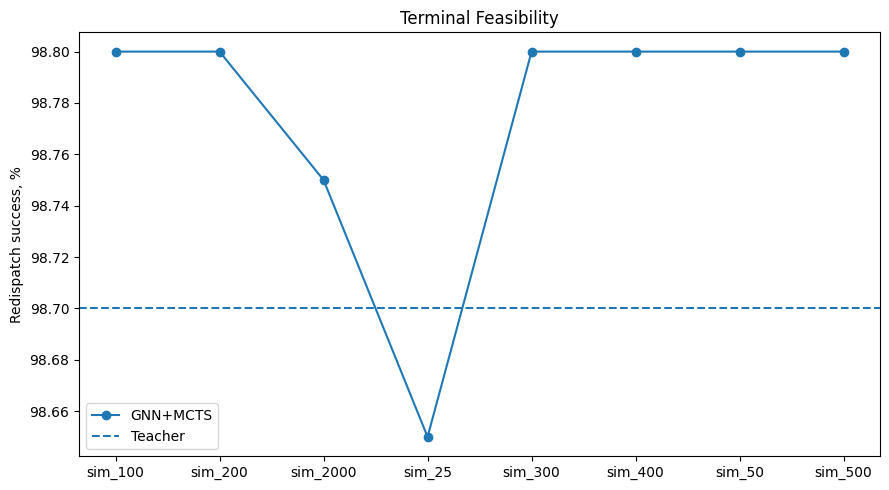

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    mcts_summary.index,
    100 * mcts_summary["redispatch_success"],
    marker="o",
    label="GNN+MCTS",
)

ax.axhline(
    100 * teacher_summary["redispatch_success"],
    linestyle="--",
    label="Teacher",
)

ax.set_ylabel("Redispatch success, %")
ax.set_title("Terminal Feasibility")
ax.legend()

plt.tight_layout()
plt.show()

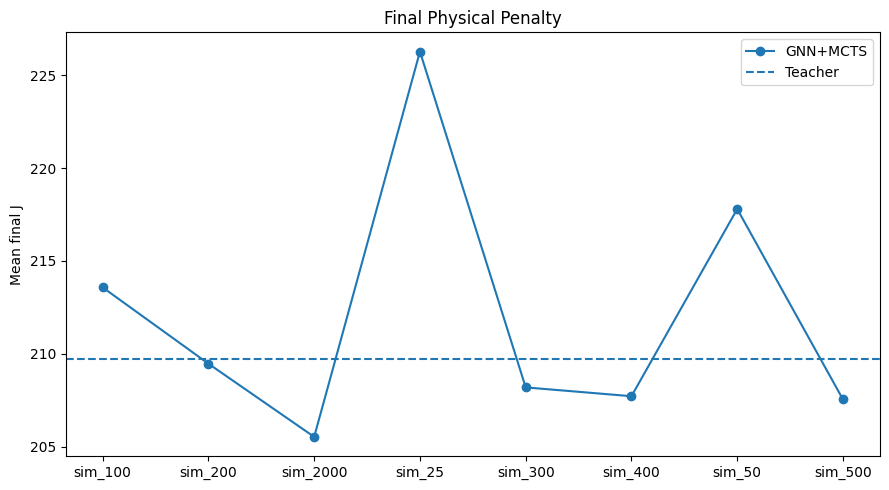

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    mcts_summary.index,
    mcts_summary["mean_J"],
    marker="o",
    label="GNN+MCTS",
)

ax.axhline(
    teacher_summary["mean_J"],
    linestyle="--",
    label="Teacher",
)

ax.set_ylabel("Mean final J")
ax.set_title("Final Physical Penalty")
ax.legend()

plt.tight_layout()
plt.show()

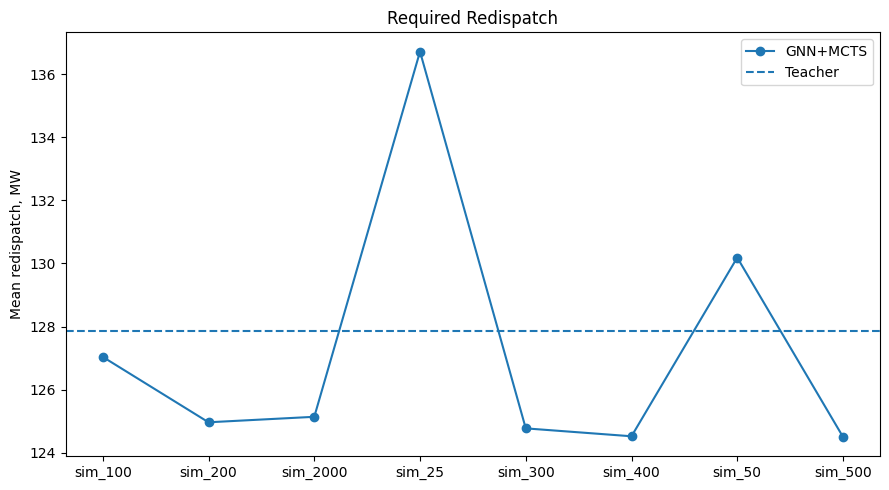

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    mcts_summary.index,
    mcts_summary["mean_redispatch"],
    marker="o",
    label="GNN+MCTS",
)

ax.axhline(
    teacher_summary["mean_redispatch"],
    linestyle="--",
    label="Teacher",
)

ax.set_ylabel("Mean redispatch, MW")
ax.set_title("Required Redispatch")
ax.legend()

plt.tight_layout()
plt.show()

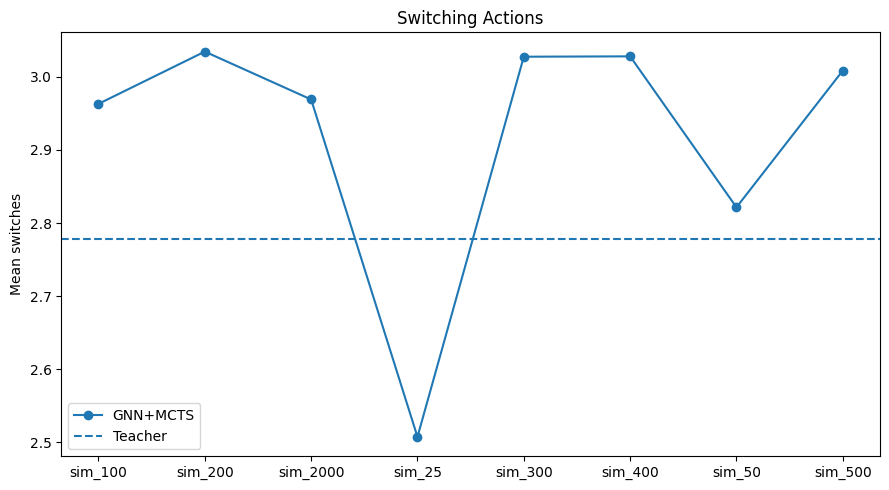

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    mcts_summary.index,
    mcts_summary["mean_switches"],
    marker="o",
    label="GNN+MCTS",
)

ax.axhline(
    teacher_summary["mean_switches"],
    linestyle="--",
    label="Teacher",
)

ax.set_ylabel("Mean switches")
ax.set_title("Switching Actions")
ax.legend()

plt.tight_layout()
plt.show()

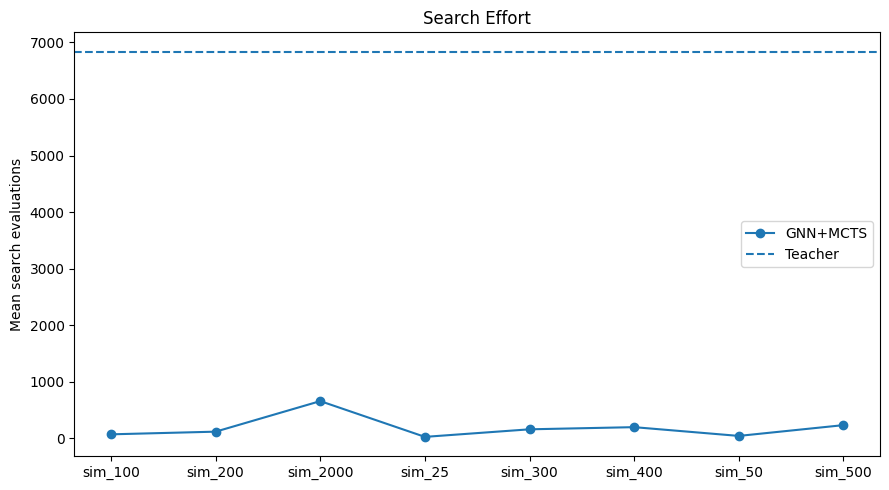

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    mcts_summary.index,
    mcts_summary["mean_search_evaluations"],
    marker="o",
    label="GNN+MCTS",
)

ax.axhline(
    teacher_summary["mean_search_evaluations"],
    linestyle="--",
    label="Teacher",
)

ax.set_ylabel("Mean search evaluations")
ax.set_title("Search Effort")
ax.legend()

plt.tight_layout()
plt.show()

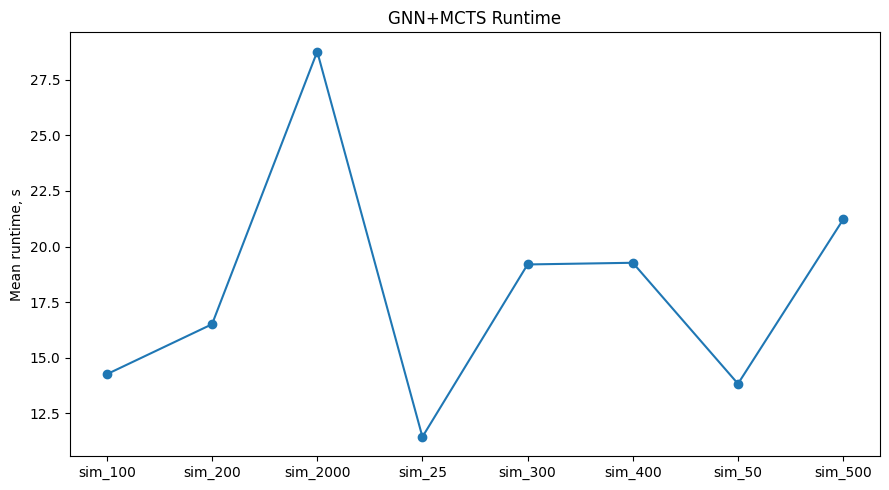

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    mcts_summary.index,
    mcts_summary["mean_runtime"],
    marker="o",
)

ax.set_ylabel("Mean runtime, s")
ax.set_title("GNN+MCTS Runtime")

plt.tight_layout()
plt.show()

## 12. Search-effort trade-off

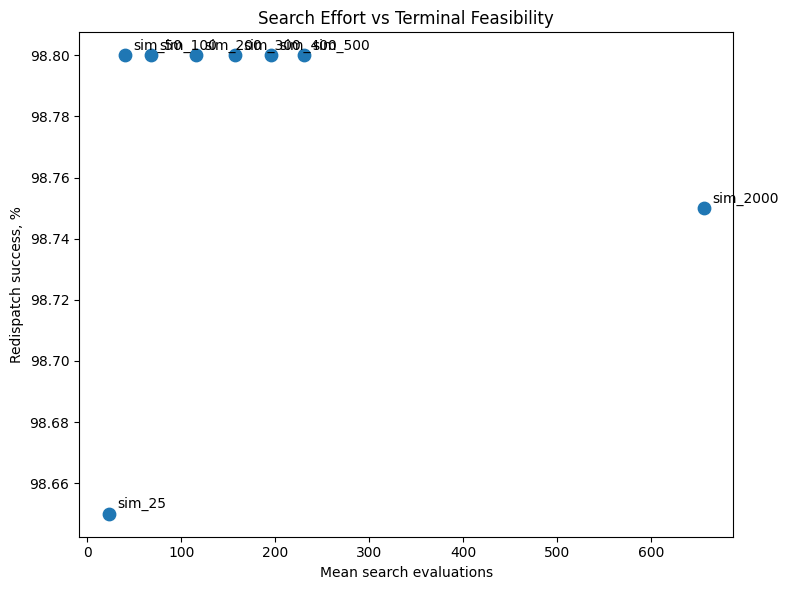

In [26]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    mcts_summary["mean_search_evaluations"],
    100 * mcts_summary["redispatch_success"],
    s=80,
)

for setting in mcts_summary.index:
    ax.annotate(
        setting,
        (
            mcts_summary.loc[setting, "mean_search_evaluations"],
            100 * mcts_summary.loc[setting, "redispatch_success"],
        ),
        xytext=(6, 4),
        textcoords="offset points",
    )

ax.set_xlabel("Mean search evaluations")
ax.set_ylabel("Redispatch success, %")
ax.set_title("Search Effort vs Terminal Feasibility")

plt.tight_layout()
plt.show()

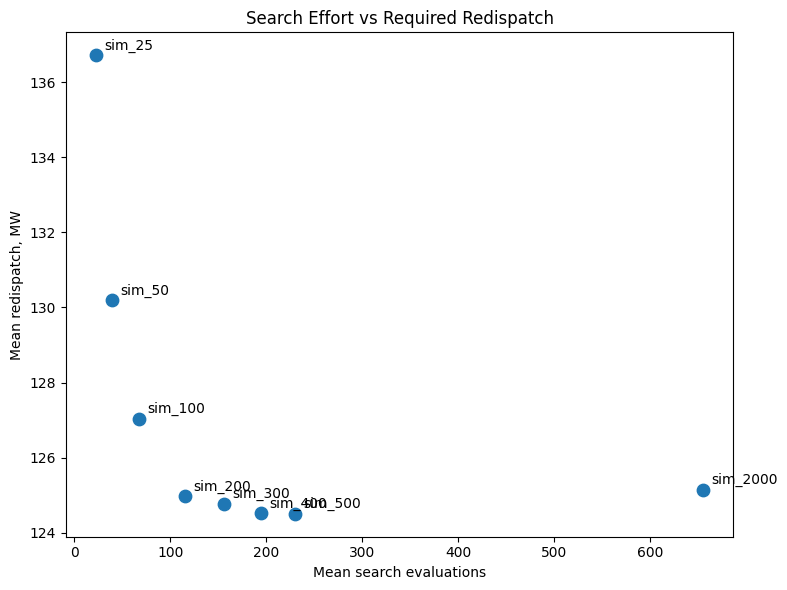

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    mcts_summary["mean_search_evaluations"],
    mcts_summary["mean_redispatch"],
    s=80,
)

for setting in mcts_summary.index:
    ax.annotate(
        setting,
        (
            mcts_summary.loc[setting, "mean_search_evaluations"],
            mcts_summary.loc[setting, "mean_redispatch"],
        ),
        xytext=(6, 4),
        textcoords="offset points",
    )

ax.set_xlabel("Mean search evaluations")
ax.set_ylabel("Mean redispatch, MW")
ax.set_title("Search Effort vs Required Redispatch")

plt.tight_layout()
plt.show()

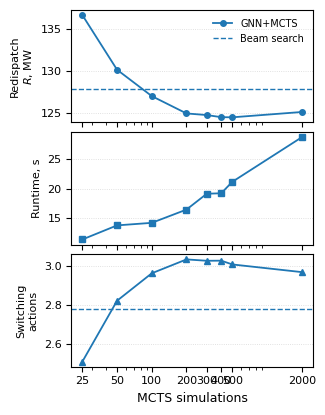

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Build plot data directly from the benchmark results
# ------------------------------------------------------------

plot_data = (
    results[results["variant"] == "gnn_mcts"]
    .groupby("setting", as_index=False)
    .agg(
        redispatch=("redispatch_l1_mw", "mean"),
        runtime=("runtime_s", "mean"),
        switches=("switches", "mean"),
    )
)

plot_data["simulations"] = (
    plot_data["setting"]
    .str.extract(r"(\d+)$")[0]
    .astype(int)
)

plot_data = (
    plot_data
    .sort_values("simulations")
    .reset_index(drop=True)
)

# Teacher is repeated for every simulation setting,
# therefore keep one row per scenario before calculating its means.
teacher_data = (
    results[results["variant"] == "teacher"]
    .drop_duplicates("scenario_id")
)

teacher_redispatch = teacher_data["redispatch_l1_mw"].mean()
teacher_runtime = teacher_data["runtime_s"].mean()
teacher_switches = teacher_data["switches"].mean()


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    1,
    figsize=(3.35, 4.25),
    sharex=True,
)

ax_r, ax_t, ax_s = axes

x = plot_data["simulations"]


# Redispatch
ax_r.plot(
    x,
    plot_data["redispatch"],
    marker="o",
    markersize=4,
    linewidth=1.3,
    label="GNN+MCTS",
)

if np.isfinite(teacher_redispatch):
    ax_r.axhline(
        teacher_redispatch,
        linestyle="--",
        linewidth=1.0,
        label="Beam search",
    )

ax_r.set_ylabel("Redispatch\n$R$, MW")
ax_r.legend(
    frameon=False,
    fontsize=7,
    loc="best",
)


# Runtime
ax_t.plot(
    x,
    plot_data["runtime"],
    marker="s",
    markersize=4,
    linewidth=1.3,
)

if np.isfinite(teacher_runtime):
    ax_t.axhline(
        teacher_runtime,
        linestyle="--",
        linewidth=1.0,
    )

ax_t.set_ylabel("Runtime, s")


# Switching actions
ax_s.plot(
    x,
    plot_data["switches"],
    marker="^",
    markersize=4,
    linewidth=1.3,
)

if np.isfinite(teacher_switches):
    ax_s.axhline(
        teacher_switches,
        linestyle="--",
        linewidth=1.0,
    )

ax_s.set_ylabel("Switching\nactions")
ax_s.set_xlabel("MCTS simulations")


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

for ax in axes:
    ax.set_xscale("log")

    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.6,
        alpha=0.5,
    )

    ax.tick_params(
        axis="both",
        labelsize=8,
    )

    ax.yaxis.label.set_size(8)


ax_s.set_xticks(x)
ax_s.set_xticklabels(
    plot_data["simulations"].astype(str),
    fontsize=8,
)

ax_s.xaxis.label.set_size(9)

plt.tight_layout(h_pad=0.35)

plt.savefig(
    "mcts_simulation_budget.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

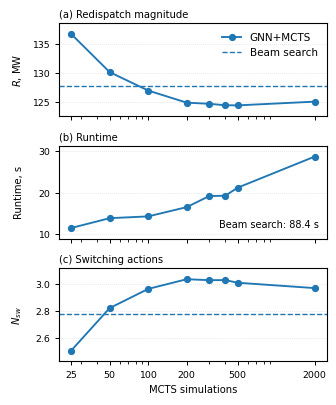

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

plot_data = mcts_summary.copy()

plot_data["simulations"] = [
    int(str(setting).split("_")[1])
    for setting in plot_data.index
]

plot_data = plot_data.sort_values("simulations")

simulations = plot_data["simulations"].to_numpy()

redispatch = plot_data["mean_redispatch"].to_numpy()
runtime = plot_data["mean_runtime"].to_numpy()
switches = plot_data["mean_switches"].to_numpy()
success = 100 * plot_data["redispatch_success"].to_numpy()

beam_redispatch = float(teacher_summary["mean_redispatch"])
beam_runtime = float(teacher_summary["mean_runtime"])
beam_switches = float(teacher_summary["mean_switches"])
beam_success = 100 * float(teacher_summary["redispatch_success"])


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.size": 7.2,
    "axes.labelsize": 7.2,
    "axes.titlesize": 7.2,
    "xtick.labelsize": 6.75,
    "ytick.labelsize": 6.75,
    "legend.fontsize": 6.75,
    "lines.linewidth": 1.35,
    "lines.markersize": 4.2,
})

fig, axes = plt.subplots(
    3,
    1,
    figsize=(3.35, 4.1),
    sharex=True,
    gridspec_kw={"hspace": 0.32}
)

ax_r, ax_t, ax_n = axes


# ------------------------------------------------------------
# (a) Redispatch
# ------------------------------------------------------------

ax_r.plot(
    simulations,
    redispatch,
    marker="o",
)

ax_r.axhline(
    beam_redispatch,
    linestyle="--",
    linewidth=1.0,
)

ax_r.set_ylabel("$R$, MW", labelpad=6)
ax_r.set_title("(a) Redispatch magnitude", loc="left", pad=4)


# ------------------------------------------------------------
# (b) Runtime
# ------------------------------------------------------------

ax_t.plot(
    simulations,
    runtime,
    marker="o",
)

ax_t.set_ylabel("Runtime, s", labelpad=6)
ax_t.set_title("(b) Runtime", loc="left", pad=4)

# Beam runtime is outside the visible MCTS scale
ax_t.text(
    0.97,
    0.10,
    f"Beam search: 88.4 s",
    transform=ax_t.transAxes,
    ha="right",
    va="bottom",
    fontsize=7,
)


# ------------------------------------------------------------
# (c) Switching actions
# ------------------------------------------------------------

ax_n.plot(
    simulations,
    switches,
    marker="o",
)

ax_n.axhline(
    beam_switches,
    linestyle="--",
    linewidth=1.0,
)

ax_n.set_ylabel("$N_{sw}$", labelpad=6)
ax_n.set_xlabel("MCTS simulations")
ax_n.set_title("(c) Switching actions", loc="left", pad=4)


# ------------------------------------------------------------
# Shared formatting
# ------------------------------------------------------------

for ax in axes:
    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.55,
        alpha=0.45,
    )

    ax.tick_params(
        direction="out",
        length=3,
        width=0.7,
    )

    ax.margins(y=0.15)
    ax.set_xscale("log")


# исправлен только вид чисел снизу
xticks_to_show = [25, 50, 100, 200, 500, 2000]
ax_n.set_xticks(xticks_to_show)
ax_n.set_xticklabels([str(x) for x in xticks_to_show])


# ------------------------------------------------------------
# Common legend
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linewidth=1.35,
        label="GNN+MCTS",
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        linewidth=1.0,
        label="Beam search",
    ),
]

ax_r.legend(
    handles=legend_handles,
    loc="upper right",
    ncol=1,
    frameon=False,
    handlelength=1.8,
    columnspacing=1.4,
    fontsize=7.5,
)

# Align all Y labels
fig.align_ylabels(axes)

plt.subplots_adjust(
    top=0.925,
    bottom=0.10,
    left=0.18,
    right=0.98,
)

plt.savefig(
    "mcts_budget_performance.png",
    dpi=600,
    bbox_inches="tight",
)

plt.savefig(
    "mcts_budget_performance.svg",
    bbox_inches="tight",
)

plt.show()

C:\Users\timof\AppData\Local\Temp\ipykernel_20756\833113192.py:70: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


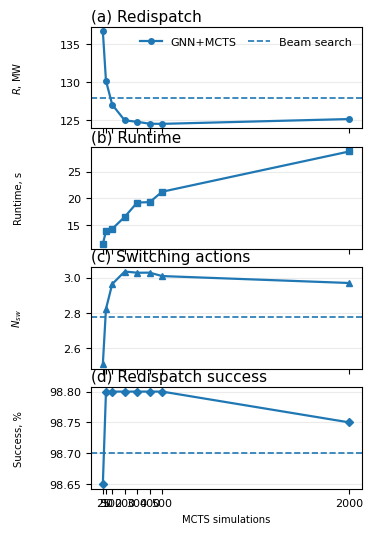

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rows = []

for setting in MCTS_SETTINGS:
    name = setting["name"]
    sim = setting["num_simulations"]

    row = mcts_summary.loc[name]

    rows.append({
        "setting": name,
        "simulations": sim,
        "redispatch": row["mean_redispatch"],
        "runtime": row["mean_runtime"],
        "switches": row["mean_switches"],
        "success": row["redispatch_success"] * 100,
    })

plot_data = pd.DataFrame(rows).sort_values("simulations")

teacher_redispatch = teacher_summary["mean_redispatch"]
teacher_runtime = teacher_summary["mean_runtime"]
teacher_switches = teacher_summary["mean_switches"]
teacher_success = teacher_summary["redispatch_success"] * 100

fig, axes = plt.subplots(
    4, 1,
    figsize=(3.5, 6.0),
    sharex=True,
    gridspec_kw={"hspace": 0.18}
)

x = plot_data["simulations"]

axes[0].plot(x, plot_data["redispatch"], marker="o", linewidth=1.6, markersize=4, label="GNN+MCTS")
axes[0].axhline(teacher_redispatch, linestyle="--", linewidth=1.2, label="Beam search")
axes[0].set_ylabel(r"$R$, MW", labelpad=18)
axes[0].set_title("(a) Redispatch", loc="left", pad=4, fontsize=11)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(frameon=False, fontsize=8, loc="upper right", ncol=2, columnspacing=1.0, handlelength=2.0)

axes[1].plot(x, plot_data["runtime"], marker="s", linewidth=1.6, markersize=4)
axes[1].axhline(teacher_runtime, linestyle="--", linewidth=1.2)
axes[1].set_ylabel("Runtime, s", labelpad=18)
axes[1].set_title("(b) Runtime", loc="left", pad=4, fontsize=11)
axes[1].grid(axis="y", alpha=0.25)

axes[2].plot(x, plot_data["switches"], marker="^", linewidth=1.6, markersize=4)
axes[2].axhline(teacher_switches, linestyle="--", linewidth=1.2)
axes[2].set_ylabel(r"$N_{sw}$", labelpad=18)
axes[2].set_title("(c) Switching actions", loc="left", pad=4, fontsize=11)
axes[2].grid(axis="y", alpha=0.25)

axes[3].plot(x, plot_data["success"], marker="D", linewidth=1.6, markersize=4)
axes[3].axhline(teacher_success, linestyle="--", linewidth=1.2)
axes[3].set_ylabel("Success, %", labelpad=18)
axes[3].set_title("(d) Redispatch success", loc="left", pad=4, fontsize=11)
axes[3].set_xlabel("MCTS simulations")
axes[3].grid(axis="y", alpha=0.25)

axes[3].set_xticks(x)

for ax in axes:
    ax.tick_params(axis="both", labelsize=8)

fig.align_ylabels(axes)
plt.tight_layout()
plt.show()

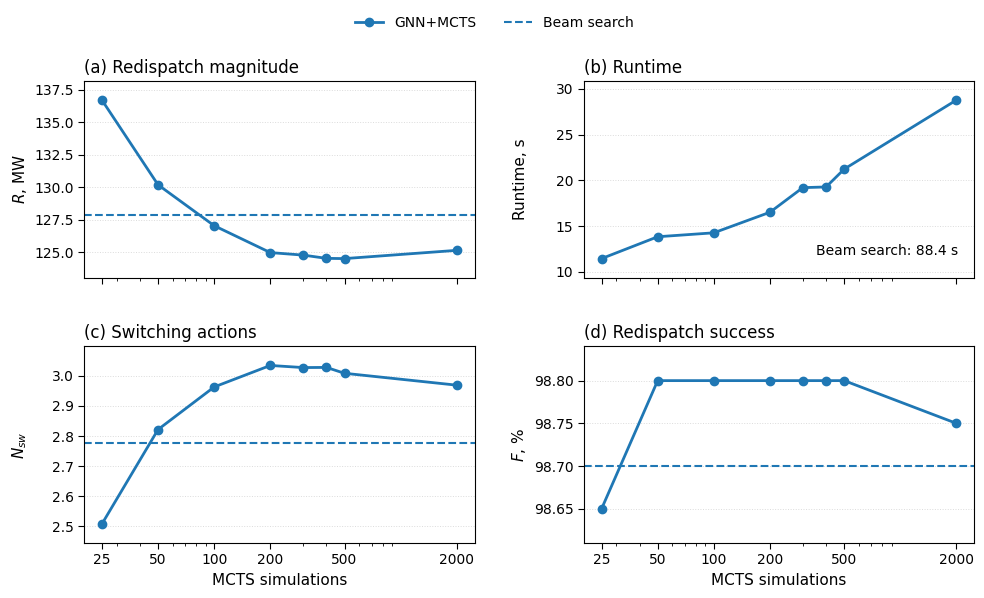

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

plot_data = mcts_summary.copy()

plot_data["simulations"] = [
    int(str(setting).split("_")[1])
    for setting in plot_data.index
]

plot_data = plot_data.sort_values("simulations")

simulations = plot_data["simulations"].to_numpy()

redispatch = plot_data["mean_redispatch"].to_numpy()
runtime = plot_data["mean_runtime"].to_numpy()
switches = plot_data["mean_switches"].to_numpy()
success = 100 * plot_data["redispatch_success"].to_numpy()

beam_redispatch = float(teacher_summary["mean_redispatch"])
beam_runtime = float(teacher_summary["mean_runtime"])
beam_switches = float(teacher_summary["mean_switches"])
beam_success = 100 * float(teacher_summary["redispatch_success"])


# ------------------------------------------------------------
# Figure style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "lines.linewidth": 2.0,
    "lines.markersize": 6,
})


# ------------------------------------------------------------
# Figure: 2 x 2
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 6),
    sharex=True,
)

ax_r = axes[0, 0]
ax_t = axes[0, 1]
ax_n = axes[1, 0]
ax_f = axes[1, 1]


# ------------------------------------------------------------
# (a) Redispatch
# ------------------------------------------------------------

ax_r.plot(
    simulations,
    redispatch,
    marker="o",
)

ax_r.axhline(
    beam_redispatch,
    linestyle="--",
    linewidth=1.5,
)

ax_r.set_ylabel("$R$, MW")
ax_r.set_title("(a) Redispatch magnitude", loc="left")


# ------------------------------------------------------------
# (b) Runtime
# ------------------------------------------------------------

ax_t.plot(
    simulations,
    runtime,
    marker="o",
)

ax_t.set_ylabel("Runtime, s")
ax_t.set_title("(b) Runtime", loc="left")

# Beam runtime is outside visible MCTS scale
ax_t.text(
    0.96,
    0.10,
    f"Beam search: 88.4 s",
    transform=ax_t.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
)


# ------------------------------------------------------------
# (c) Switching actions
# ------------------------------------------------------------

ax_n.plot(
    simulations,
    switches,
    marker="o",
)

ax_n.axhline(
    beam_switches,
    linestyle="--",
    linewidth=1.5,
)

ax_n.set_ylabel("$N_{sw}$")
ax_n.set_xlabel("MCTS simulations")
ax_n.set_title("(c) Switching actions", loc="left")


# ------------------------------------------------------------
# (d) Redispatch success
# ------------------------------------------------------------

ax_f.plot(
    simulations,
    success,
    marker="o",
)

ax_f.axhline(
    beam_success,
    linestyle="--",
    linewidth=1.5,
)

ax_f.set_ylabel("$F$, %")
ax_f.set_xlabel("MCTS simulations")
ax_f.set_title("(d) Redispatch success", loc="left")


# ------------------------------------------------------------
# Shared formatting
# ------------------------------------------------------------

for ax in axes.flat:

    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.7,
        alpha=0.45,
    )

    ax.tick_params(
        direction="out",
        length=4,
        width=0.8,
    )

    ax.margins(y=0.12)
    ax.set_xscale("log")


# X ticks only on lower panels
# X ticks only on lower panels
xticks_to_show = [25, 50, 100, 200, 500, 2000]

for ax in (ax_n, ax_f):
    ax.set_xticks(xticks_to_show)
    ax.set_xticklabels([str(x) for x in xticks_to_show])

# ------------------------------------------------------------
# Success-rate scale
# ------------------------------------------------------------

success_all = np.append(success, beam_success)

span = success_all.max() - success_all.min()
margin = max(0.04, span * 0.25)

ax_f.set_ylim(
    success_all.min() - margin,
    success_all.max() + margin,
)


# ------------------------------------------------------------
# Common legend
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linewidth=2.0,
        label="GNN+MCTS",
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        linewidth=1.5,
        label="Beam search",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01),
)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

fig.align_ylabels(axes[:, 0])
fig.align_ylabels(axes[:, 1])

plt.subplots_adjust(
    top=0.88,
    bottom=0.11,
    left=0.09,
    right=0.98,
    hspace=0.35,
    wspace=0.28,
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "mcts_budget_performance_2x2.png",
    dpi=600,
    bbox_inches="tight",
)

plt.savefig(
    "mcts_budget_performance_2x2.svg",
    bbox_inches="tight",
)

plt.show()

## 13. Detailed Teacher comparison

In [32]:
analysis = results[
    results["setting"] == ANALYSIS_SETTING
].copy()

teacher = (
    analysis[
        analysis["variant"] == "teacher"
    ]
    .set_index("scenario_id")
)

mcts = (
    analysis[
        analysis["variant"] == "gnn_mcts"
    ]
    .set_index("scenario_id")
)

paired = teacher.join(
    mcts,
    lsuffix="_teacher",
    rsuffix="_mcts",
)

paired["delta_J"] = (
    paired["Jfinal_mcts"]
    - paired["Jfinal_teacher"]
)

paired["delta_redispatch"] = (
    paired["redispatch_l1_mw_mcts"]
    - paired["redispatch_l1_mw_teacher"]
)

print("Setting:", ANALYSIS_SETTING)
print("Paired scenarios:", len(paired))

display(
    paired[
        [
            "difficulty_teacher",
            "Jfinal_teacher",
            "Jfinal_mcts",
            "delta_J",
            "redispatch_l1_mw_teacher",
            "redispatch_l1_mw_mcts",
            "delta_redispatch",
        ]
    ].head()
)

Setting: sim_100
Paired scenarios: 2000


,difficulty_teacher,Jfinal_teacher,Jfinal_mcts,delta_J,redispatch_l1_mw_teacher,redispatch_l1_mw_mcts,delta_redispatch
scenario_id,,,,,,,
12754,hard,306.973595,274.518265,-32.455330,203.042633,191.455745,-11.586888
12760,hard,652.916884,673.467677,20.550793,NaN,NaN,NaN
12778,hard,1206.839496,1248.889453,42.049957,770.387059,751.310005,-19.077054
12779,hard,378.337702,391.967829,13.630127,238.511560,248.917469,10.405908
12794,hard,669.083550,690.439341,21.355791,NaN,NaN,NaN


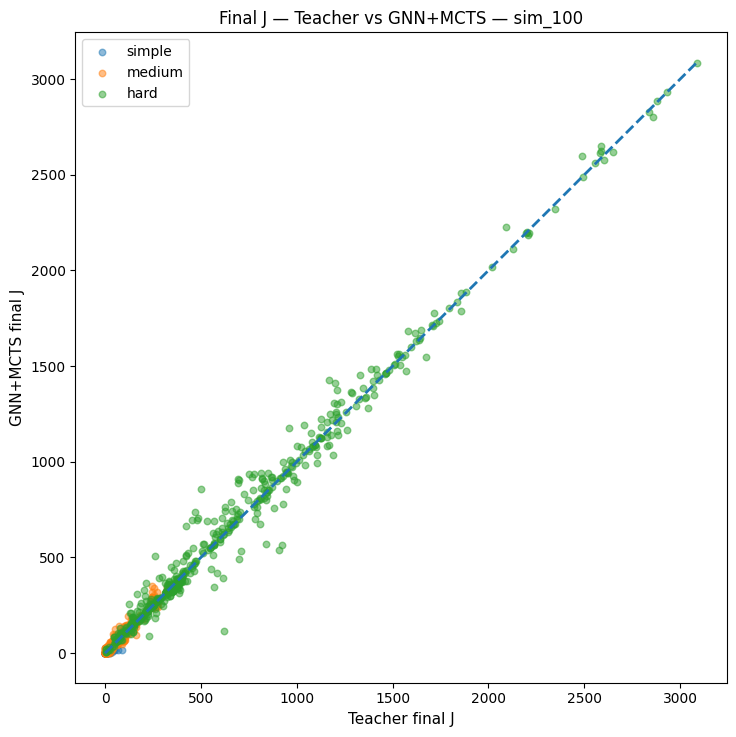

In [33]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))

for difficulty in ["simple", "medium", "hard"]:
    data = paired[
        paired["difficulty_teacher"] == difficulty
    ]

    ax.scatter(
        data["Jfinal_teacher"],
        data["Jfinal_mcts"],
        s=22,
        alpha=0.5,
        label=difficulty,
    )

limit = max(
    paired["Jfinal_teacher"].max(),
    paired["Jfinal_mcts"].max(),
)

ax.plot(
    [0, limit],
    [0, limit],
    "--",
)

ax.set_xlabel("Teacher final J")
ax.set_ylabel("GNN+MCTS final J")
ax.set_title(f"Final J — Teacher vs GNN+MCTS — {ANALYSIS_SETTING}")
ax.legend()

plt.tight_layout()
plt.show()

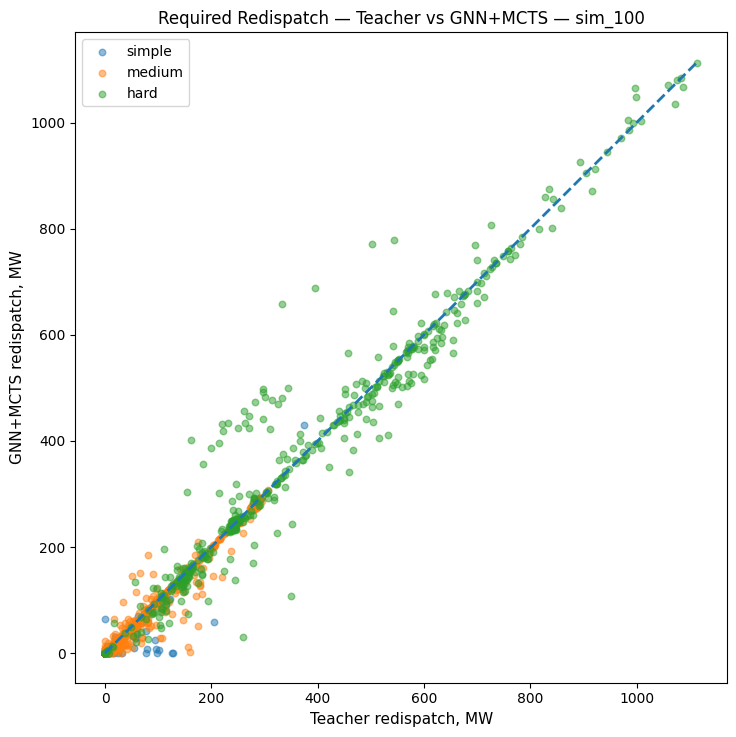

In [34]:
redispatch_data = paired[
    paired["redispatch_l1_mw_teacher"].notna()
    & paired["redispatch_l1_mw_mcts"].notna()
].copy()

fig, ax = plt.subplots(figsize=(7.5, 7.5))

for difficulty in ["simple", "medium", "hard"]:
    data = redispatch_data[
        redispatch_data["difficulty_teacher"] == difficulty
    ]

    ax.scatter(
        data["redispatch_l1_mw_teacher"],
        data["redispatch_l1_mw_mcts"],
        s=22,
        alpha=0.5,
        label=difficulty,
    )

limit = max(
    redispatch_data["redispatch_l1_mw_teacher"].max(),
    redispatch_data["redispatch_l1_mw_mcts"].max(),
)

ax.plot(
    [0, limit],
    [0, limit],
    "--",
)

ax.set_xlabel("Teacher redispatch, MW")
ax.set_ylabel("GNN+MCTS redispatch, MW")
ax.set_title(f"Required Redispatch — Teacher vs GNN+MCTS — {ANALYSIS_SETTING}")
ax.legend()

plt.tight_layout()
plt.show()

## 14. Redispatch advantage profile

In [35]:
comparison = redispatch_data.reset_index()[
    [
        "scenario_id",
        "difficulty_teacher",
        "redispatch_l1_mw_teacher",
        "redispatch_l1_mw_mcts",
    ]
].copy()

comparison = comparison.rename(
    columns={
        "difficulty_teacher": "difficulty",
        "redispatch_l1_mw_teacher": "teacher_redispatch",
        "redispatch_l1_mw_mcts": "mcts_redispatch",
    }
)

comparison["winner"] = np.where(
    comparison["mcts_redispatch"] < comparison["teacher_redispatch"],
    "mcts",
    np.where(
        comparison["teacher_redispatch"] < comparison["mcts_redispatch"],
        "teacher",
        "equal",
    ),
)

denominator = comparison[
    ["teacher_redispatch", "mcts_redispatch"]
].max(axis=1)

comparison["advantage_pct"] = np.where(
    denominator > 0,
    100
    * np.abs(
        comparison["teacher_redispatch"]
        - comparison["mcts_redispatch"]
    )
    / denominator,
    0.0,
)

thresholds = np.linspace(0, 100, 201)
total_cases = len(comparison)

mcts_share = []
teacher_share = []

for threshold in thresholds:
    mcts_share.append(
        100
        * (
            (comparison["winner"] == "mcts")
            & (comparison["advantage_pct"] >= threshold)
        ).sum()
        / total_cases
    )

    teacher_share.append(
        100
        * (
            (comparison["winner"] == "teacher")
            & (comparison["advantage_pct"] >= threshold)
        ).sum()
        / total_cases
    )

mcts_share = np.array(mcts_share)
teacher_share = np.array(teacher_share)

mcts_area = np.trapz(
    mcts_share,
    thresholds,
)

teacher_area = np.trapz(
    teacher_share,
    thresholds,
)

mcts_score = mcts_area / 100
teacher_score = teacher_area / 100
net_score = mcts_score - teacher_score

mcts_win_rate = 100 * (comparison["winner"] == "mcts").mean()
teacher_win_rate = 100 * (comparison["winner"] == "teacher").mean()
equal_rate = 100 * (comparison["winner"] == "equal").mean()

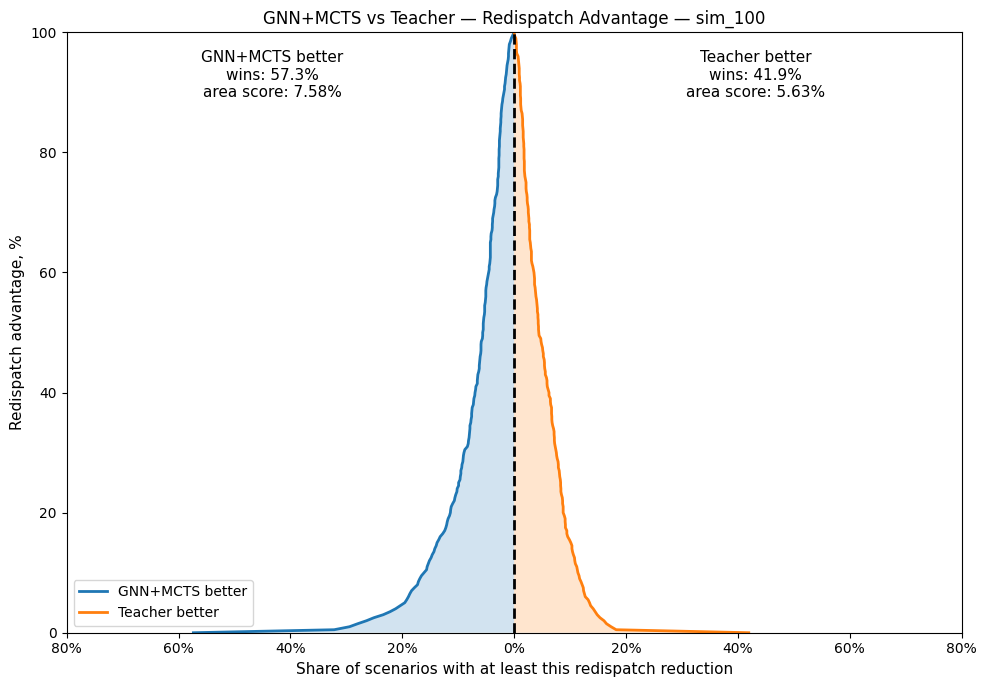

Comparable scenarios: 1974
GNN+MCTS better: 57.35%
Teacher better:  41.95%
Equal:           0.71%
GNN+MCTS area score: 7.58%
Teacher area score:  5.63%
Net advantage:       +1.95%


In [36]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    -mcts_share,
    thresholds,
    linewidth=2,
    label="GNN+MCTS better",
)

ax.fill_betweenx(
    thresholds,
    -mcts_share,
    0,
    alpha=0.2,
)

ax.plot(
    teacher_share,
    thresholds,
    linewidth=2,
    label="Teacher better",
)

ax.fill_betweenx(
    thresholds,
    0,
    teacher_share,
    alpha=0.2,
)

ax.axvline(
    0,
    linestyle="--",
    color="black",
)

max_share = max(
    mcts_share.max(),
    teacher_share.max(),
)

ax.set_xlim(
    -max_share * 1.15,
    max_share * 1.15,
)

ax.set_ylim(0, 100)

ticks = ax.get_xticks()

ax.set_xticks(ticks)

ax.set_xticklabels(
    [f"{abs(x):.0f}%" for x in ticks]
)

ax.set_xlabel(
    "Share of scenarios with at least this redispatch reduction"
)

ax.set_ylabel(
    "Redispatch advantage, %"
)

ax.set_title(
    f"GNN+MCTS vs Teacher — Redispatch Advantage — {ANALYSIS_SETTING}"
)

ax.text(
    0.23,
    0.97,
    (
        "GNN+MCTS better\n"
        f"wins: {mcts_win_rate:.1f}%\n"
        f"area score: {mcts_score:.2f}%"
    ),
    transform=ax.transAxes,
    ha="center",
    va="top",
)

ax.text(
    0.77,
    0.97,
    (
        "Teacher better\n"
        f"wins: {teacher_win_rate:.1f}%\n"
        f"area score: {teacher_score:.2f}%"
    ),
    transform=ax.transAxes,
    ha="center",
    va="top",
)

ax.legend()

plt.tight_layout()
plt.show()

print(f"Comparable scenarios: {total_cases}")
print(f"GNN+MCTS better: {mcts_win_rate:.2f}%")
print(f"Teacher better:  {teacher_win_rate:.2f}%")
print(f"Equal:           {equal_rate:.2f}%")
print(f"GNN+MCTS area score: {mcts_score:.2f}%")
print(f"Teacher area score:  {teacher_score:.2f}%")
print(f"Net advantage:       {net_score:+.2f}%")

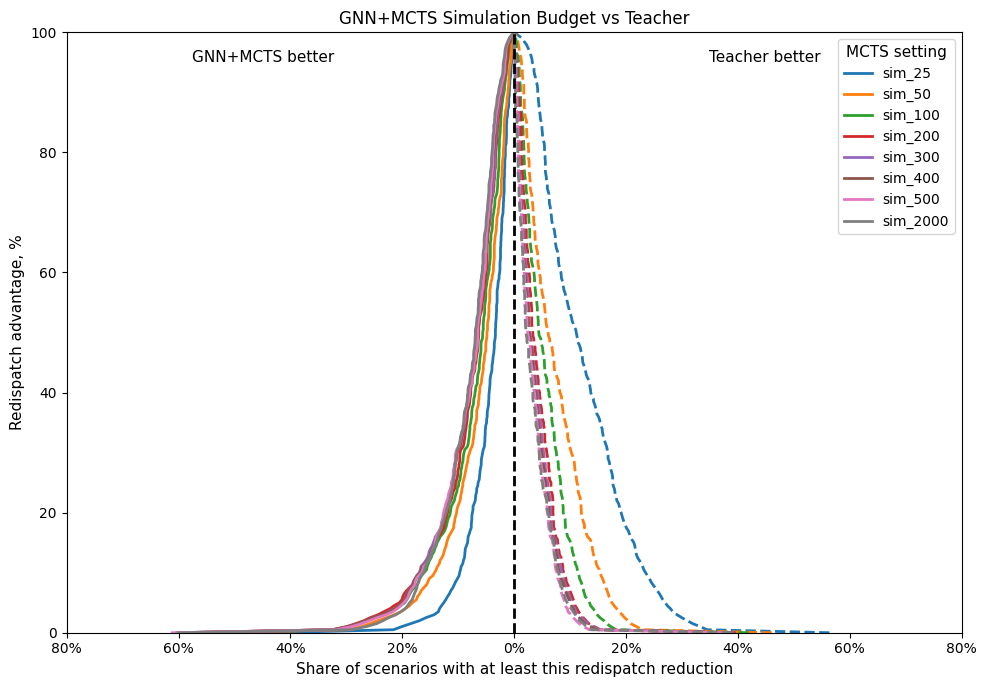

In [37]:
thresholds = np.linspace(0, 100, 201)

fig, ax = plt.subplots(figsize=(10, 7))

for setting in [x["name"] for x in MCTS_SETTINGS]:
    data = results[
        (results["setting"] == setting)
        & results["variant"].isin(["teacher", "gnn_mcts"])
    ]

    comparison = (
        data
        .pivot_table(
            index=["scenario_id", "difficulty"],
            columns="variant",
            values="redispatch_l1_mw",
            aggfunc="first",
        )
        .reset_index()
    )

    comparison = comparison.rename(
        columns={
            "teacher": "teacher_redispatch",
            "gnn_mcts": "mcts_redispatch",
        }
    )

    comparison = comparison[
        comparison["teacher_redispatch"].notna()
        & comparison["mcts_redispatch"].notna()
    ].copy()

    denominator = comparison[
        ["teacher_redispatch", "mcts_redispatch"]
    ].max(axis=1)

    comparison["advantage_pct"] = np.where(
        denominator > 0,
        100
        * np.abs(
            comparison["teacher_redispatch"]
            - comparison["mcts_redispatch"]
        )
        / denominator,
        0.0,
    )

    comparison["winner"] = np.where(
        comparison["mcts_redispatch"]
        < comparison["teacher_redispatch"],
        "mcts",
        np.where(
            comparison["teacher_redispatch"]
            < comparison["mcts_redispatch"],
            "teacher",
            "equal",
        ),
    )

    total_cases = len(comparison)

    mcts_share = []
    teacher_share = []

    for threshold in thresholds:
        mcts_share.append(
            100
            * (
                (comparison["winner"] == "mcts")
                & (comparison["advantage_pct"] >= threshold)
            ).sum()
            / total_cases
        )

        teacher_share.append(
            100
            * (
                (comparison["winner"] == "teacher")
                & (comparison["advantage_pct"] >= threshold)
            ).sum()
            / total_cases
        )

    mcts_share = np.array(mcts_share)
    teacher_share = np.array(teacher_share)

    line, = ax.plot(
        -mcts_share,
        thresholds,
        linewidth=2,
        label=setting,
    )

    ax.plot(
        teacher_share,
        thresholds,
        linewidth=2,
        linestyle="--",
        color=line.get_color(),
    )

ax.axvline(
    0,
    linestyle="--",
    color="black",
)

ax.set_xlim(-80, 80)
ax.set_ylim(0, 100)

ticks = ax.get_xticks()

ax.set_xticks(ticks)
ax.set_xticklabels(
    [f"{abs(x):.0f}%" for x in ticks]
)

ax.set_xlabel(
    "Share of scenarios with at least this redispatch reduction"
)

ax.set_ylabel(
    "Redispatch advantage, %"
)

ax.set_title(
    "GNN+MCTS Simulation Budget vs Teacher"
)

ax.text(
    0.22,
    0.97,
    "GNN+MCTS better",
    transform=ax.transAxes,
    ha="center",
    va="top",
)

ax.text(
    0.78,
    0.97,
    "Teacher better",
    transform=ax.transAxes,
    ha="center",
    va="top",
)

ax.legend(
    title="MCTS setting"
)

plt.tight_layout()
plt.show()

## 15. Tail robustness

In [38]:
comparison["redispatch_advantage_pct"] = np.where(
    comparison["winner"] == "mcts",
    comparison["advantage_pct"],
    np.where(
        comparison["winner"] == "teacher",
        -comparison["advantage_pct"],
        0.0,
    ),
)

percentiles = [1, 5, 10, 50, 90, 95, 99]

redispatch_tail = pd.DataFrame({
    "Percentile": percentiles,
    "GNN+MCTS redispatch advantage, %": [
        np.percentile(
            comparison["redispatch_advantage_pct"],
            p,
        )
        for p in percentiles
    ],
})

display(redispatch_tail.round(2))

,Percentile,"GNN+MCTS redispatch advantage, %"
0,1,-70.51
1,5,-25.08
2,10,-4.27
3,50,0.00
4,90,30.83
5,95,68.11
6,99,98.62


In [39]:
rows = []

for difficulty in ["simple", "medium", "hard"]:
    data = comparison[
        comparison["difficulty"] == difficulty
    ]["redispatch_advantage_pct"]

    rows.append({
        "Difficulty": difficulty,
        "1% worst": np.percentile(data, 1),
        "5% worst": np.percentile(data, 5),
        "10% worst": np.percentile(data, 10),
        "Median": np.percentile(data, 50),
        "10% best": np.percentile(data, 90),
        "5% best": np.percentile(data, 95),
        "1% best": np.percentile(data, 99),
    })

redispatch_tail_by_difficulty = pd.DataFrame(rows)

display(
    redispatch_tail_by_difficulty.round(2)
)

,Difficulty,1% worst,5% worst,10% worst,Median,10% best,5% best,1% best
0,simple,-71.07,-27.02,-0.00,0.0,73.19,93.76,99.69
1,medium,-75.64,-25.23,-4.72,0.0,20.82,57.52,95.33
2,hard,-41.67,-19.83,-5.14,0.0,17.29,32.96,69.32


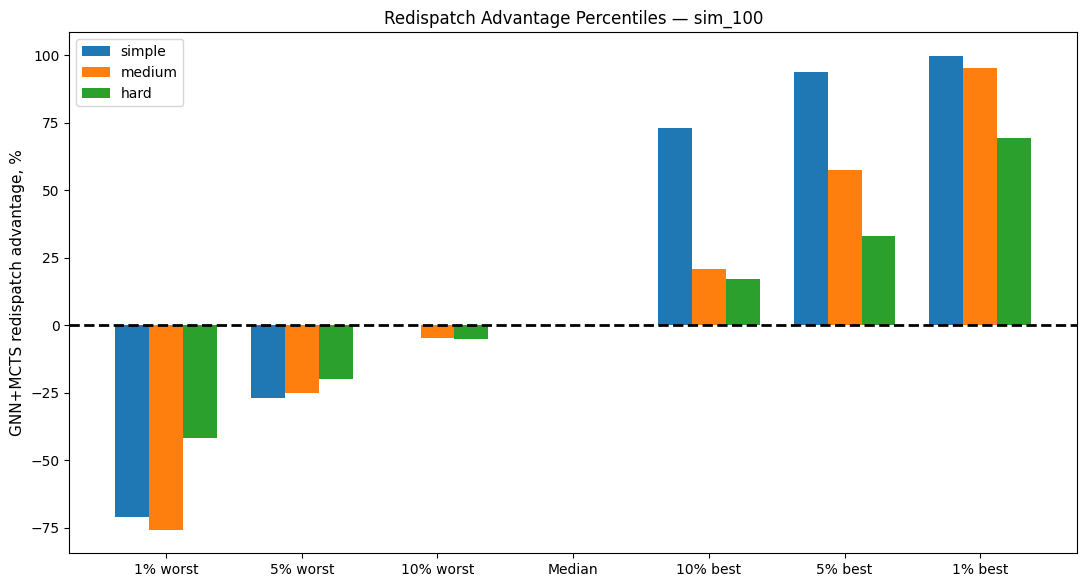

In [40]:
metrics = [
    "1% worst",
    "5% worst",
    "10% worst",
    "Median",
    "10% best",
    "5% best",
    "1% best",
]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for i, difficulty in enumerate(["simple", "medium", "hard"]):
    row = redispatch_tail_by_difficulty[
        redispatch_tail_by_difficulty["Difficulty"] == difficulty
    ].iloc[0]

    values = [
        row[metric]
        for metric in metrics
    ]

    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=difficulty,
    )

ax.axhline(
    0,
    linestyle="--",
    color="black",
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.set_ylabel(
    "GNN+MCTS redispatch advantage, %"
)

ax.set_title(
    f"Redispatch Advantage Percentiles — {ANALYSIS_SETTING}"
)

ax.legend()

plt.tight_layout()
plt.show()

## 16. Summary table for article

In [41]:
columns = [
    "redispatch_success",
    "mean_J",
    "mean_redispatch",
    "mean_switches",
    "mean_search_evaluations",
    "mean_runtime",
]

article_table = mcts_summary[columns].copy()

article_table = article_table.loc[
    sorted(
        article_table.index,
        key=lambda x: int(x.split("_")[1]),
    )
]

teacher_row = (
    teacher_summary[columns]
    .to_frame()
    .T
)

teacher_row.index = ["Teacher"]

article_table = pd.concat(
    [
        teacher_row,
        article_table,
    ]
)

article_table["redispatch_success"] *= 100

article_table.columns = [
    "Redispatch success, %",
    "Mean final J",
    "Mean redispatch, MW",
    "Mean switches",
    "Mean search evaluations",
    "Mean runtime, s",
]

display(article_table.round(2))

,"Redispatch success, %",Mean final J,"Mean redispatch, MW",Mean switches,Mean search evaluations,"Mean runtime, s"
Teacher,98.70,209.72,127.86,2.78,6838.55,NaN
sim_25,98.65,226.27,136.71,2.51,22.76,11.45
sim_50,98.80,217.79,130.19,2.82,39.70,13.83
sim_100,98.80,213.57,127.04,2.96,67.75,14.26
sim_200,98.80,209.46,124.97,3.03,114.98,16.51
sim_300,98.80,208.19,124.77,3.03,156.48,19.20
sim_400,98.80,207.71,124.52,3.03,194.70,19.27
sim_500,98.80,207.54,124.50,3.01,230.31,21.22
sim_2000,98.75,205.52,125.14,2.97,655.49,28.77


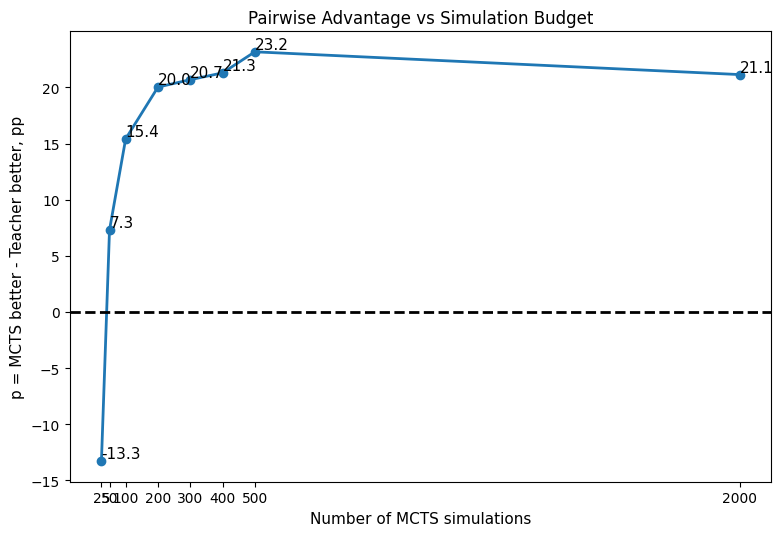

,setting,simulations,p,mcts_win,teacher_win
0,sim_25,25,-13.31,43.12,56.42
1,sim_50,50,7.30,53.40,46.10
2,sim_100,100,15.42,57.40,41.99
3,sim_200,200,20.03,59.69,39.66
4,sim_300,300,20.69,60.04,39.35
5,sim_400,400,21.30,60.29,39.00
6,sim_500,500,23.17,61.21,38.03
7,sim_2000,2000,21.15,60.14,39.00


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rows = []

for setting in [x["name"] for x in MCTS_SETTINGS]:
    data = results[
        (results["setting"] == setting)
        & results["variant"].isin(["teacher", "gnn_mcts"])
    ]

    comparison = (
        data
        .pivot_table(
            index="scenario_id",
            columns="variant",
            values="redispatch_l1_mw",
            aggfunc="first",
        )
        .reset_index()
    )

    comparison = comparison.rename(
        columns={
            "teacher": "teacher_redispatch",
            "gnn_mcts": "mcts_redispatch",
        }
    )

    comparison = comparison[
        comparison["teacher_redispatch"].notna()
        & comparison["mcts_redispatch"].notna()
    ].copy()

    comparison = comparison[
        (comparison["teacher_redispatch"] > 0)
        | (comparison["mcts_redispatch"] > 0)
    ].copy()

    comparison["winner"] = np.where(
        comparison["mcts_redispatch"] < comparison["teacher_redispatch"],
        "mcts",
        np.where(
            comparison["teacher_redispatch"] < comparison["mcts_redispatch"],
            "teacher",
            "equal",
        ),
    )

    mcts_win = 100 * (comparison["winner"] == "mcts").mean()
    teacher_win = 100 * (comparison["winner"] == "teacher").mean()

    p = mcts_win - teacher_win

    rows.append({
        "setting": setting,
        "simulations": int(setting.split("_")[1]),
        "p": p,
        "mcts_win": mcts_win,
        "teacher_win": teacher_win,
    })

plot_data = pd.DataFrame(rows).sort_values("simulations")

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    plot_data["simulations"],
    plot_data["p"],
    marker="o",
    linewidth=2,
)

ax.axhline(
    0,
    linestyle="--",
    color="black",
)

for row in plot_data.itertuples():
    ax.text(
        row.simulations,
        row.p,
        f"{row.p:.1f}",
        ha="left",
        va="bottom",
    )

ax.set_xticks(plot_data["simulations"])

ax.set_xlabel(
    "Number of MCTS simulations"
)

ax.set_ylabel(
    "p = MCTS better - Teacher better, pp"
)

ax.set_title(
    "Pairwise Advantage vs Simulation Budget"
)

plt.tight_layout()
plt.show()

display(plot_data.round(2))

In [49]:
import time
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx

from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from IPython.display import Video, display

from grid_topology_ai.state import BRANCH_FEATURE_COLUMNS
from grid_topology_ai.physics.objective import assess_physical_state


# ============================================================
# 1. USER SETTINGS
# ============================================================

SCENARIO_ID = None
NUM_SIMULATIONS = 200

# Rendering: 12 x 9 inches at 160 DPI -> 1920 x 1440 pixels (4:3).
FPS = 30
VIDEO_DPI = 160

# The three introductory explanations each last exactly four seconds.
EXPLAINER_SECONDS = 4.0
FADE_SECONDS = 0.6

# Timing: use longer candidate explanations only for the first switch.
INITIAL_SECONDS = 0.7
CANDIDATE_FADE_SECONDS = 0.55
FIRST_SCORE_FADE_SECONDS = 0.65
FIRST_SCORE_HOLD_SECONDS = 3.5
NEXT_SCORE_FADE_SECONDS = 0.4
NEXT_SCORE_HOLD_SECONDS = 1.5
CHOOSE_SECONDS = 0.65
SELECTION_HOLD_SECONDS = 0.9
APPLY_SECONDS = 1.6
RESULT_HOLD_SECONDS = 1.35
FINAL_HOLD_SECONDS = 0.75
COMPARISON_SECONDS = 5.0

MAKE_GIF = False
# Set a measured Beam time for THIS scenario to skip the Beam rerun.
# Leave None to measure Beam search using the original dataset settings.
BEAM_RUNTIME_S = 149.32  # e.g. 150.59

OUTPUT_DIR = PROJECT_DIR / "notebooks" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. FFMPEG
# ============================================================

try:
    import imageio_ffmpeg

    mpl.rcParams["animation.ffmpeg_path"] = (
        imageio_ffmpeg.get_ffmpeg_exe()
    )

except ImportError:
    pass

if not FFMpegWriter.isAvailable():
    raise RuntimeError(
        "FFmpeg is unavailable. "
        "Run %pip install imageio-ffmpeg first."
    )


# ============================================================
# 3. SELECT PROCESSED SCENARIO
# ============================================================

setting = next(
    (
        dict(s)
        for s in MCTS_SETTINGS
        if int(s["num_simulations"]) == NUM_SIMULATIONS
    ),
    None,
)

if setting is None:
    setting = dict(
        next(
            s for s in MCTS_SETTINGS
            if int(s["num_simulations"]) == 200
        )
    )

    setting["name"] = f"sim_{NUM_SIMULATIONS}"
    setting["num_simulations"] = NUM_SIMULATIONS


if SCENARIO_ID is None:

    reference = f"sim_{NUM_SIMULATIONS}"

    if reference not in set(results["setting"]):
        reference = "sim_200"

    pool = results.loc[
        (results["setting"] == reference)
        & (results["variant"] == "gnn_mcts")
        & (results["redispatch_validated"] == True)
        & results["redispatch_l1_mw"].notna()
        & (results["switches"] >= 2)
    ].copy()

    pool = pool.loc[
        pool["scenario_id"].isin(teacher_baseline)
    ].copy()

    pool["beam_R"] = pool["scenario_id"].map(
        lambda sid: teacher_baseline[int(sid)]["redispatch_l1_mw"]
    )

    pool = pool.loc[
        np.isfinite(pool["beam_R"])
        & (pool["beam_R"] >= 15)
    ].copy()

    if pool.empty:
        raise ValueError(
            "No suitable processed scenario found. "
            "Set SCENARIO_ID manually."
        )

    pool["gain"] = (
        pool["beam_R"] - pool["redispatch_l1_mw"]
    )

    improved = pool.loc[pool["gain"] > 0]

    if not improved.empty:
        pool = improved

    pool["difficulty_weight"] = (
        pool["difficulty"]
        .map({"hard": 2, "medium": 1, "simple": 0})
        .fillna(0)
    )

    pool = pool.sort_values(
        ["difficulty_weight", "gain"],
        ascending=False,
    )

    SCENARIO_ID = int(pool.iloc[0]["scenario_id"])


SCENARIO_ID = int(SCENARIO_ID)

row = scenarios.loc[
    scenarios["scenario_id"] == SCENARIO_ID
]

if row.empty or SCENARIO_ID not in teacher_baseline:
    raise ValueError(
        f"Scenario or Beam search baseline missing: {SCENARIO_ID}"
    )

difficulty = str(row.iloc[0]["difficulty_class"])


# ============================================================
# 4. REAL MCTS SEARCH AND PARETO SELECTION
# ============================================================

search = run_mcts_search(
    SCENARIO_ID,
    difficulty,
    setting,
)

all_nodes = all_mcts_candidates(search["result"])

rd_backend = new_backend()
rd_cache = {}

started = time.perf_counter()

selected_node, selected_rd, *_ = no_stop_pareto_candidate(
    all_nodes,
    rd_backend,
    rd_cache,
    setting["pareto_per_switch_count"],
)

selection_time_s = time.perf_counter() - started

mcts_runtime = (
    float(search["initial_time_s"])
    + float(search["search_time_s"])
    + selection_time_s
)


# ============================================================
# 5. REPLAY ACTUAL SWITCHING TRAJECTORY
# ============================================================

recorded_actions = [
    action
    for action in selected_node.env.applied_actions
    if (
        action.branch_id is not None
        and action.action_type != "do_nothing"
    )
]

if not recorded_actions:
    raise ValueError(
        "The selected Pareto trajectory contains no switches."
    )

_, max_steps = mcts_horizon(
    difficulty,
    setting,
)

replay_env = new_env(
    max_steps=max_steps,
    backend=search["backend"],
)

replay_env.reset(SCENARIO_ID)

states = [replay_env.current_state]
actions = []

for original in recorded_actions:

    result = replay_env.step(
        int(original.action_id),
        compute_reward=False,
    )

    if (
        not result.power_flow_success
        or result.next_state is None
    ):
        raise RuntimeError(
            f"AC PF failed while replaying branch "
            f"{original.branch_id}"
        )

    expected = (
        int(original.branch_id),
        int(original.target_status),
    )

    actual = (
        int(result.action.branch_id),
        int(result.action.target_status),
    )

    if actual != expected:
        raise RuntimeError(
            "Replayed action does not match the selected trajectory."
        )

    actions.append(result.action)
    states.append(result.next_state)


# ============================================================
# 6. EXTRACT PHYSICAL METRICS AND GNN OUTPUTS
# ============================================================

loading_idx = BRANCH_FEATURE_COLUMNS.index(
    "loading_percent"
)

action_space = new_action_space()
snapshots = []

for step, state in enumerate(states):

    mask = np.asarray(
        action_space.operational_action_mask(state),
        dtype=bool,
    ).copy()

    # STOP is not included among switching candidates.
    mask[0] = False

    legal_ids = np.flatnonzero(mask)

    if not mask.any():
        mask[0] = True

    policy, value = evaluator.evaluate(
        state,
        mask,
    )

    top3_ids = sorted(
        legal_ids,
        key=lambda aid: float(policy[aid]),
        reverse=True,
    )[:3]

    top3 = [
        (
            int(state.branch_ids[aid - 1]),
            float(policy[aid]),
        )
        for aid in top3_ids
    ]

    secure = bool(
        assess_physical_state(state.metrics).physically_secure
    )

    if secure:
        redispatch = 0.0

    else:
        rd = (
            selected_rd
            if (
                step == len(states) - 1
                and selected_rd is not None
            )
            else cached_redispatch(
                rd_backend,
                state,
                rd_cache,
            )
        )

        redispatch = (
            float(rd.redispatch_l1_mw)
            if (
                rd.validated
                and rd.redispatch_l1_mw is not None
            )
            else np.nan
        )

    snapshots.append({
        "loading": np.asarray(
            state.branch_features[:, loading_idx],
            dtype=float,
        ),
        "active": np.asarray(
            state.branch_status,
            dtype=bool,
        ),
        "R": redispatch,
        "V": float(value),
        "secure": secure,
        "top3": top3,
    })


beam_R = float(
    teacher_baseline[SCENARIO_ID]["redispatch_l1_mw"]
)

# ============================================================
# 6A. BEAM SEARCH: DATASET CONFIGURATION AND MEASURED TIME
# ============================================================
# The validation dataset stores the Beam result, but its
# teacher_baseline[scenario_id]["runtime_s"] is NaN.
# Rerun ONLY the chosen scenario with the exact Teacher
# task_config stored in teacher_checkpoint_config.json.
#
# Timing matches teacher_runtime.py: planner.search() plus
# redispatch-aware terminal selection. Initial AC OPF is
# prepared beforehand, as in the original dataset generator.

if BEAM_RUNTIME_S is not None:
    BEAM_RUNTIME_S = float(BEAM_RUNTIME_S)

    if not np.isfinite(BEAM_RUNTIME_S) or BEAM_RUNTIME_S < 0:
        raise ValueError("BEAM_RUNTIME_S must be a finite, nonnegative number.")

    # Use the saved Beam redispatch baseline for this scenario.
    # IMPORTANT: supplied time must correspond to the same scenario/settings.
    print(
        f"Using supplied Beam time: {BEAM_RUNTIME_S:.2f} s. "
        "Beam search rerun skipped."
    )
else:
    from grid_topology_ai.config import PhysicsConfig
    from grid_topology_ai.search.teacher import (
        ImpactBeamSearchConfig,
        ImpactBeamSearchPlanner,
        LODFScreenedImpactBeamSearchPlanner,
        _redispatch_aware_selection,
    )

    beam_task = dict(teacher_tasks[difficulty])

    # Use the dataset's physics settings rather than assuming the
    # GNN checkpoint and the Teacher use identical configurations.
    beam_physics = PhysicsConfig.from_mapping(beam_task["physics_config"])
    beam_cache_enabled = not bool(beam_task.get("disable_cache", False))

    beam_adapter = GridFMAdapter(
        RAW_DIR,
        physics_config=beam_physics,
    )
    beam_backend = GridFMPowerFlowBackend(
        adapter=beam_adapter,
        physics_config=beam_physics,
        enable_cache=beam_cache_enabled,
    )
    beam_env = TopologySwitchingEnv(
        adapter=beam_adapter,
        backend=beam_backend,
        action_space=GridFMActionSpace(
            require_connected_after_switch=True,
            enable_cache=beam_cache_enabled,
        ),
        reward_fn=GridFMReward(physics_config=beam_physics),
        max_steps=int(beam_task["max_steps"]),
    )

    beam_config = ImpactBeamSearchConfig(
        max_depth=int(beam_task["depth"]),
        beam_width=int(beam_task["beam_width"]),
        candidate_pool_size=int(beam_task["candidate_pool"]),
        top_k_actions=int(beam_task["top_k"]),
        redispatch_candidates_per_switch_count=int(
            beam_task["redispatch_candidates_per_switch_count"]
        ),
        gamma=float(beam_task["gamma"]),
        allow_hard_count_increase=bool(beam_task["allow_hard_count_increase"]),
        show_progress=False,
        progress_update_every=10,
    )

    if bool(beam_task["use_lodf_screening"]):
        beam_planner = LODFScreenedImpactBeamSearchPlanner(
            config=beam_config,
            lodf_screen_top_k=int(beam_task["lodf_screen_top_k"]),
            lodf_min_candidate_count=int(beam_task["lodf_min_candidate_count"]),
            physics_config=beam_physics,
        )
    else:
        beam_planner = ImpactBeamSearchPlanner(
            beam_config,
            physics_config=beam_physics,
        )

    # The source dataset computes initial redispatch before timing
    # the Beam search. Keep this preprocessing out of the displayed
    # Beam timer so the measured scope matches teacher_runtime.py.
    beam_preparation_start = time.perf_counter()
    beam_initial_state = beam_env.reset(SCENARIO_ID)
    beam_initial_redispatch = run_minimal_ac_redispatch(
        beam_backend,
        beam_initial_state,
    )
    beam_preparation_s = time.perf_counter() - beam_preparation_start

    print(
        "Rerunning Beam search with dataset task_config: "
        f"scenario={SCENARIO_ID}, depth={beam_config.max_depth}, "
        f"width={beam_config.beam_width}, "
        f"LODF={bool(beam_task['use_lodf_screening'])}"
    )

    beam_search_start = time.perf_counter()
    beam_result = beam_planner.search(
        env=beam_env,
        scenario_id=SCENARIO_ID,
    )
    beam_search_s = time.perf_counter() - beam_search_start

    beam_selection_start = time.perf_counter()
    beam_result, beam_selection = _redispatch_aware_selection(
        beam_result,
        task_config=beam_task,
        initial_redispatch_result=beam_initial_redispatch,
    )
    beam_selection_s = time.perf_counter() - beam_selection_start

    # This is a REAL measurement for this one scenario, not an
    # average from the validation set or an invented estimate.
    BEAM_RUNTIME_S = beam_search_s + beam_selection_s

    # Verify the fresh result against the stored baseline.
    beam_selected_rd = beam_selection.get("_selected_redispatch_result")
    beam_state = beam_result.best_node.env.current_state

    if assess_physical_state(beam_state.metrics).physically_secure:
        beam_rerun_R = 0.0
    elif (
        beam_selected_rd is not None
        and beam_selected_rd.validated
        and beam_selected_rd.redispatch_l1_mw is not None
    ):
        beam_rerun_R = float(beam_selected_rd.redispatch_l1_mw)
    else:
        # Only needed when terminal selection did not return
        # a validated redispatch result. This final verification
        # is outside the dataset-equivalent search timer.
        beam_final_rd = run_minimal_ac_redispatch(
            beam_backend,
            beam_state,
        )
        beam_rerun_R = (
            float(beam_final_rd.redispatch_l1_mw)
            if beam_final_rd.validated
            and beam_final_rd.redispatch_l1_mw is not None
            else np.nan
        )

    if not np.isfinite(beam_rerun_R):
        raise RuntimeError(
            "Rerun Beam search found no validated redispatch; "
            "cannot show a trustworthy time/results pair."
        )

    if not np.isclose(beam_R, beam_rerun_R, rtol=0.01, atol=1.0):
        print(
            "WARNING: Fresh Beam result differs from saved baseline: "
            f"saved={beam_R:.2f} MW, rerun={beam_rerun_R:.2f} MW. "
            "The video will use the measured rerun result."
        )

    # Keep redispatch and time from the SAME measured execution.
    beam_R = beam_rerun_R

    print(
        f"Beam search: {beam_search_s:.2f} s; "
        f"terminal selection: {beam_selection_s:.2f} s; "
        f"DISPLAYED TIME: {BEAM_RUNTIME_S:.2f} s"
    )
    print(
        f"Beam preparation (excluded, as in dataset): "
        f"{beam_preparation_s:.2f} s; "
        f"final redispatch: {beam_R:.2f} MW"
    )

print(
    f"Scenario {SCENARIO_ID} | "
    f"{difficulty} | "
    f"{NUM_SIMULATIONS} simulations"
)

print(
    "Switches:",
    [
        (int(a.branch_id), int(a.target_status))
        for a in actions
    ]
)

print(
    f"GNN+MCTS: {snapshots[-1]['R']:.2f} MW, "
    f"{mcts_runtime:.2f} s"
)

print(f"Beam search: {beam_R:.2f} MW")


# ============================================================
# 7. STATIC NETWORK LAYOUT
# ============================================================

state0 = states[0]

edge_index = np.asarray(
    state0.edge_index,
    dtype=int,
)

branch_ids = np.asarray(
    state0.branch_ids,
    dtype=int,
)

branch_pos = {
    int(branch_id): k
    for k, branch_id in enumerate(branch_ids)
}

num_buses = len(state0.bus_features)

network = nx.Graph()
network.add_nodes_from(range(num_buses))

network.add_edges_from(
    (int(u), int(v))
    for u, v in edge_index.T
)

position = nx.spring_layout(
    network,
    seed=42,
    iterations=250,
    k=0.19,
)

xy = np.asarray([
    position[i]
    for i in range(num_buses)
])


# ------------------------------------------------------------
# Separate parallel physical branches visually
# ------------------------------------------------------------

pairs = defaultdict(list)

for k, (u, v) in enumerate(edge_index.T):
    pairs[tuple(sorted((int(u), int(v))))].append(k)

edge_lengths = [
    float(np.linalg.norm(xy[int(u)] - xy[int(v)]))
    for u, v in edge_index.T
]

separation = (
    0.18 * float(np.median(edge_lengths))
)

segments = [None] * len(branch_ids)

for pair, indices in pairs.items():

    u, v = pair

    p0 = xy[u]
    p1 = xy[v]

    direction = p1 - p0
    direction /= max(
        float(np.linalg.norm(direction)),
        1e-9,
    )

    perpendicular = np.array([
        -direction[1],
        direction[0],
    ])

    for order, k in enumerate(indices):

        offset = (
            order - (len(indices) - 1) / 2
        ) * separation

        midpoint = (
            (p0 + p1) / 2
            + offset * perpendicular
        )

        segments[k] = np.asarray([
            p0,
            midpoint,
            p1,
        ])

segments = np.asarray(segments)

xmin, ymin = xy.min(axis=0)
xmax, ymax = xy.max(axis=0)

span_x = xmax - xmin
span_y = ymax - ymin


# ============================================================
# 8. VISUAL STYLE
# ============================================================

WHITE = "#ffffff"
DARK = "#27343c"
MUTED = "#6c7882"

NORMAL = "#aeb5ba"
OFF_COLOR = "#d6dadd"

RED = "#d84b43"
BLUE = "#2586b8"
GREEN = "#23945e"
METRIC_NEUTRAL = "#000000"  # Initial/unchanged metric color


def mix(a, b, t):
    a = np.asarray(to_rgb(a))
    b = np.asarray(to_rgb(b))
    return tuple((1 - t) * a + t * b)


def loading_color(value):

    if not np.isfinite(value) or value < 90:
        return NORMAL

    if value < 100:
        return mix(
            NORMAL,
            "#f6b5ae",
            (value - 90) / 10,
        )

    if value < 120:
        return mix(
            "#f6b5ae",
            "#eb4b45",
            (value - 100) / 20,
        )

    return mix(
        "#eb4b45",
        "#a30f1c",
        min((value - 120) / 80, 1),
    )


def load_width(value):

    if not np.isfinite(value) or value < 100:
        return 1.0

    return 1.5 + 2.4 * min(
        (value - 100) / 40,
        1.0,
    )


def smooth(t):
    t = float(np.clip(t, 0, 1))
    return t * t * (3 - 2 * t)


def callout_alpha(progress):

    elapsed = progress * EXPLAINER_SECONDS

    return min(
        smooth(elapsed / FADE_SECONDS),
        smooth(
            (EXPLAINER_SECONDS - elapsed) / FADE_SECONDS
        ),
    )


def max_loading(snapshot):

    mask = (
        snapshot["active"]
        & np.isfinite(snapshot["loading"])
    )

    if not np.any(mask):
        return np.nan

    return float(
        np.max(snapshot["loading"][mask])
    )


# ============================================================
# 9. ANIMATION TIMELINE
# ============================================================

frames = []


def stage(step, phase, duration):

    count = max(
        2,
        int(round(duration * FPS)),
    )

    for i in range(count):
        progress = i / (count - 1)
        frames.append((step, phase, progress))


stage(0, "initial", INITIAL_SECONDS)
stage(0, "red_card", EXPLAINER_SECONDS)

for step in range(len(actions)):
    first_step = step == 0

    # Introduce blue candidate lines, then the one-time explanation.
    stage(step, "blue_in", CANDIDATE_FADE_SECONDS)
    if first_step:
        stage(step, "blue_card", EXPLAINER_SECONDS)

    # Allow time to understand candidate probabilities on the first step.
    score_fade = (
        FIRST_SCORE_FADE_SECONDS
        if first_step else NEXT_SCORE_FADE_SECONDS
    )
    score_hold = (
        FIRST_SCORE_HOLD_SECONDS
        if first_step else NEXT_SCORE_HOLD_SECONDS
    )
    stage(step, "scores_in", score_fade)
    stage(step, "scores_hold", score_hold)

    # Identify the selected switching action *before* numbers change.
    stage(step, "choose", CHOOSE_SECONDS)
    if first_step:
        # One-time green explanation also acts as the first selection hold.
        stage(step, "green_card", EXPLAINER_SECONDS)
    else:
        stage(step, "selected_hold", SELECTION_HOLD_SECONDS)

    # Recalculate the visual state, then hold the new physical results.
    # The green line remains visible throughout both phases.
    stage(step + 1, "apply", APPLY_SECONDS)
    stage(step + 1, "result_hold", RESULT_HOLD_SECONDS)

stage(len(actions), "final", FINAL_HOLD_SECONDS)
stage(len(actions), "comparison", COMPARISON_SECONDS)

# ============================================================
# 10. TIMELINE VALIDATION
# ============================================================

phase_names = [phase for _, phase, _ in frames]

for phase in ("red_card", "blue_card", "green_card"):

    starts = sum(
        current == phase and previous != phase
        for previous, current in zip(
            [None] + phase_names[:-1],
            phase_names,
        )
    )

    if starts != 1:
        raise AssertionError(
            f"{phase} must occur exactly once."
        )


for step in range(len(actions)):

    phases = [
        phase
        for s, phase, _ in frames
        if s == step
    ]

    phases = list(dict.fromkeys(
        p for p in phases
        if p in (
            "blue_in",
            "blue_card",
            "scores_in",
            "choose",
        )
    ))

    expected = ["blue_in"]

    if step == 0:
        expected.append("blue_card")

    expected += ["scores_in", "choose"]

    if phases != expected:
        raise AssertionError(
            f"Incorrect phase order at step {step}: {phases}"
        )

print(
    f"Animation: {len(frames) / FPS:.1f} s, "
    f"{len(frames)} frames, {len(actions)} switching actions"
)


# ============================================================
# 11. FIGURE: NETWORK ABOVE, TWO METRIC COLUMNS BELOW
# ============================================================

# Preserve the original 4:3 video format. The network now uses
# nearly the entire frame width, since the V(s) panel is removed.
fig = plt.figure(
    figsize=(12, 9),
    dpi=VIDEO_DPI,
    facecolor=WHITE,
)

ax_net = fig.add_axes([
    0.045, 0.23, 0.91, 0.73,
])

ax_net.set_xlim(
    xmin - 0.08 * span_x,
    xmax + 0.08 * span_x,
)
ax_net.set_ylim(
    ymin - 0.11 * span_y,
    ymax + 0.11 * span_y,
)
ax_net.set_aspect("equal")

# Stable positions: initial physical metrics will fade out here,
# then Beam search and GNN+MCTS will appear in exactly these slots.
LEFT_COLUMN_X = 0.39
RIGHT_COLUMN_X = 0.61
LABEL_Y = 0.166
VALUE_Y = 0.105
TIME_Y = 0.061

def bottom_text(x, y, value, *, size, color, bold=False):
    return fig.text(
        x,
        y,
        value,
        fontsize=size,
        fontweight="bold" if bold else "normal",
        color=color,
        ha="center",
        va="bottom",
        alpha=1.0,
    )


# Values shown while the network is being reconfigured.
metric_labels = [
    bottom_text(
        LEFT_COLUMN_X, LABEL_Y, "REQUIRED REDISPATCH",
        size=11, color=MUTED,
    ),
    bottom_text(
        RIGHT_COLUMN_X, LABEL_Y, "MAX. LINE LOADING",
        size=11, color=MUTED,
    ),
]

text_R = bottom_text(
    LEFT_COLUMN_X, VALUE_Y, "",
    size=21, color=METRIC_NEUTRAL, bold=True,
)
text_L = bottom_text(
    RIGHT_COLUMN_X, VALUE_Y, "",
    size=21, color=METRIC_NEUTRAL, bold=True,
)

# Direction indicators. Two artists per metric allow a smooth
# crossfade when the trend reverses between consecutive states.
def make_trend_arrows():
    up = bottom_text(0, VALUE_Y, "↑", size=21, color=RED, bold=True)
    down = bottom_text(0, VALUE_Y, "↓", size=21, color=GREEN, bold=True)

    for arrow in (up, down):
        arrow.set_ha("left")
        arrow.set_alpha(0.0)

    return up, down


arrows_R = make_trend_arrows()
arrows_L = make_trend_arrows()
metric_arrows = (*arrows_R, *arrows_L)

# Initially invisible. Updated for each comparison frame.
beam_time_text = (
    f"{BEAM_RUNTIME_S:.2f} s"
    if BEAM_RUNTIME_S is not None and np.isfinite(BEAM_RUNTIME_S)
    else "Time not recorded"
)
final_R = float(snapshots[-1]["R"])
final_R_text = (
    f"{final_R:.1f} MW" if np.isfinite(final_R)
    else "OPF not feasible"
)

comparison_artists = {
    "beam": [
        bottom_text(
            LEFT_COLUMN_X, LABEL_Y, "BEAM SEARCH",
            size=11, color=MUTED,
        ),
        bottom_text(
            LEFT_COLUMN_X, VALUE_Y, f"{beam_R:.1f} MW",
            size=21, color=DARK, bold=True,
        ),
        bottom_text(
            LEFT_COLUMN_X, TIME_Y, beam_time_text,
            size=21, color=DARK, bold=True,
        ),
    ],
    "mcts": [
        bottom_text(
            RIGHT_COLUMN_X, LABEL_Y, "GNN + MCTS",
            size=11, color=GREEN,
        ),
        bottom_text(
            RIGHT_COLUMN_X, VALUE_Y, final_R_text,
            size=21, color=GREEN, bold=True,
        ),
        bottom_text(
            RIGHT_COLUMN_X, TIME_Y, f"{mcts_runtime:.2f} s",
            size=21, color=GREEN, bold=True,
        ),
    ],
}

for artists in comparison_artists.values():
    for artist in artists:
        artist.set_alpha(0.0)

# ============================================================
# HORIZONTAL VALUE BAR (Chess-style evaluation indicator)
# ============================================================

# Kept above the two bottom metrics, outside the network itself.
# V(s) is the GNN state value, NOT the probability of success.
VALUE_BAR_X = 0.355
VALUE_BAR_Y = 0.205
VALUE_BAR_WIDTH = 0.29
VALUE_BAR_HEIGHT = 0.024

value_bar_negative = Rectangle(
    (VALUE_BAR_X, VALUE_BAR_Y),
    VALUE_BAR_WIDTH / 2,
    VALUE_BAR_HEIGHT,
    transform=fig.transFigure,
    facecolor=RED,
    edgecolor="none",
    zorder=20,
)
value_bar_positive = Rectangle(
    (VALUE_BAR_X + VALUE_BAR_WIDTH / 2, VALUE_BAR_Y),
    VALUE_BAR_WIDTH / 2,
    VALUE_BAR_HEIGHT,
    transform=fig.transFigure,
    facecolor=GREEN,
    edgecolor="none",
    zorder=20,
)
value_bar_border = Rectangle(
    (VALUE_BAR_X, VALUE_BAR_Y),
    VALUE_BAR_WIDTH,
    VALUE_BAR_HEIGHT,
    transform=fig.transFigure,
    facecolor="none",
    edgecolor=DARK,
    linewidth=0.7,
    zorder=21,
)
value_bar_marker = Rectangle(
    (VALUE_BAR_X + VALUE_BAR_WIDTH / 2 - 0.0015, VALUE_BAR_Y - 0.007),
    0.003,
    VALUE_BAR_HEIGHT + 0.014,
    transform=fig.transFigure,
    facecolor=DARK,
    edgecolor="none",
    zorder=22,
)

for patch in (
    value_bar_negative,
    value_bar_positive,
    value_bar_border,
    value_bar_marker,
):
    fig.add_artist(patch)

value_bar_left_label = fig.text(
    VALUE_BAR_X - 0.013,
    VALUE_BAR_Y + VALUE_BAR_HEIGHT / 2,
    "−1",
    fontsize=11,
    color=MUTED,
    ha="right",
    va="center",
)
value_bar_right_label = fig.text(
    VALUE_BAR_X + VALUE_BAR_WIDTH + 0.013,
    VALUE_BAR_Y + VALUE_BAR_HEIGHT / 2,
    "+1",
    fontsize=11,
    color=MUTED,
    ha="left",
    va="center",
)
value_bar_readout = fig.text(
    0.5,
    VALUE_BAR_Y + VALUE_BAR_HEIGHT + 0.008,
    "",
    fontsize=12,
    fontweight="medium",
    color=DARK,
    ha="center",
    va="bottom",
)
value_bar_artists = (
    value_bar_negative,
    value_bar_positive,
    value_bar_border,
    value_bar_marker,
    value_bar_left_label,
    value_bar_right_label,
    value_bar_readout,
)

fig.canvas.draw()


# ============================================================
# 12. COLLISION-FREE CANDIDATE LABEL PLACEMENT
# ============================================================

label_cache = {}


def cross2d(a, b):
    return float(a[0] * b[1] - a[1] * b[0])


def segments_cross(a, b, c, d):
    """
    Test whether two leader-line segments intersect.
    """

    r = b - a
    s = d - c

    denominator = cross2d(r, s)

    if abs(denominator) < 1e-9:
        return False

    t = cross2d(c - a, s) / denominator
    u = cross2d(c - a, r) / denominator

    return (
        0 < t < 1
        and 0 < u < 1
    )


def segment_hits_rectangle(a, b, rect):
    """
    Check whether a leader line enters a label rectangle.
    """

    x0, y0, x1, y1 = rect

    corners = [
        np.array([x0, y0]),
        np.array([x1, y0]),
        np.array([x1, y1]),
        np.array([x0, y1]),
    ]

    for i in range(4):
        if segments_cross(
            a,
            b,
            corners[i],
            corners[(i + 1) % 4],
        ):
            return True

    return False


def measured_label_size(label):
    """
    Measure label dimensions in display pixels.
    Includes approximate bbox padding.
    """

    artist = fig.text(
        0, 0,
        label,
        fontsize=10.3,
        fontweight="bold",
    )

    bounds = artist.get_window_extent(
        renderer=fig.canvas.get_renderer()
    )

    artist.remove()

    return (
        bounds.width + 20,
        bounds.height + 16,
    )


def candidate_label_layout(step):
    """
    Global placement of all candidate labels.

    Labels are arranged on one side of the candidate
    branches and kept in the same vertical order as
    their targets.

    Every proposed layout is checked for:
      - overlapping label boxes
      - leader lines crossing other boxes
      - leader lines crossing one another
      - labels leaving the drawing area

    If no valid layout exists, use a leader-free fallback.
    """

    if step in label_cache:
        return label_cache[step]

    items = []

    for rank, (bid, prior) in enumerate(
        snapshots[step]["top3"],
        start=1,
    ):

        anchor = segments[
            branch_pos[int(bid)]
        ][1]

        label = f"#{rank}  {prior:.1%}"

        items.append({
            "rank": rank,
            "branch_id": int(bid),
            "label": label,
            "anchor": anchor,
            "target_px": ax_net.transData.transform(anchor),
            "size": measured_label_size(label),
        })

    if not items:
        label_cache[step] = []
        return []

    bounds = ax_net.get_window_extent()

    max_w = max(item["size"][0] for item in items)
    max_h = max(item["size"][1] for item in items)

    targets = np.asarray([
        item["target_px"]
        for item in items
    ])

    x_min = targets[:, 0].min()
    x_max = targets[:, 0].max()
    mean_y = targets[:, 1].mean()

    n = len(items)
    order = sorted(
        range(n),
        key=lambda i: targets[i, 1],
        reverse=True,
    )

    best_layout = None
    best_cost = np.inf

    # Try both sides and several possible distances.
    for side in (-1, 1):

        for distance in (120, 150, 190, 240, 300, 370):

            label_x = (
                x_min - distance
                if side == -1
                else x_max + distance
            )

            if not (
                bounds.x0 + max_w / 2 + 8
                <= label_x
                <= bounds.x1 - max_w / 2 - 8
            ):
                continue

            for spacing in (
                max_h + 12,
                max_h + 24,
                max_h + 40,
                max_h + 60,
            ):

                for shift in (
                    0, 30, -30, 65, -65,
                    100, -100, 150, -150,
                ):

                    placements = [None] * n
                    rectangles = []
                    leaders = []

                    valid = True

                    for slot, i in enumerate(order):

                        item = items[i]
                        width, height = item["size"]

                        label_y = (
                            mean_y
                            + shift
                            + ((n - 1) / 2 - slot) * spacing
                        )

                        cx = label_x
                        cy = label_y

                        rect = (
                            cx - width / 2,
                            cy - height / 2,
                            cx + width / 2,
                            cy + height / 2,
                        )

                        if (
                            rect[0] < bounds.x0 + 8
                            or rect[1] < bounds.y0 + 8
                            or rect[2] > bounds.x1 - 8
                            or rect[3] > bounds.y1 - 8
                        ):
                            valid = False
                            break

                        # Leader starts outside the label box.
                        start_x = (
                            rect[2] + 2
                            if side == -1
                            else rect[0] - 2
                        )

                        leader_start = np.array([
                            start_x,
                            cy,
                        ])

                        leader_end = item["target_px"]

                        # All anchors must be on the opposite
                        # side of the label column.
                        if (
                            side == -1
                            and leader_end[0] <= leader_start[0] + 5
                        ):
                            valid = False
                            break

                        if (
                            side == 1
                            and leader_end[0] >= leader_start[0] - 5
                        ):
                            valid = False
                            break

                        placements[i] = {
                            **item,
                            "label_px": np.array([cx, cy]),
                            "leader_start": leader_start,
                            "leader_end": leader_end,
                            "rect": rect,
                            "leader": True,
                        }

                        rectangles.append(rect)
                        leaders.append(
                            (leader_start, leader_end)
                        )

                    if not valid:
                        continue

                    # Reject intersecting leader lines.
                    for i in range(n):
                        for j in range(i + 1, n):

                            if segments_cross(
                                *leaders[i],
                                *leaders[j],
                            ):
                                valid = False
                                break

                        if not valid:
                            break

                    if not valid:
                        continue

                    # Reject leaders passing through
                    # another candidate's label.
                    for i in range(n):
                        for j in range(n):

                            if i == j:
                                continue

                            if segment_hits_rectangle(
                                *leaders[i],
                                rectangles[j],
                            ):
                                valid = False
                                break

                        if not valid:
                            break

                    if not valid:
                        continue

                    # Prefer short leader lines and avoid
                    # placing labels over dense node clusters.
                    cost = 0.0
                    node_px = ax_net.transData.transform(xy)

                    for item in placements:

                        a = item["leader_start"]
                        b = item["leader_end"]

                        cost += np.linalg.norm(b - a)

                        x0, y0, x1, y1 = item["rect"]

                        inside = (
                            (node_px[:, 0] >= x0)
                            & (node_px[:, 0] <= x1)
                            & (node_px[:, 1] >= y0)
                            & (node_px[:, 1] <= y1)
                        )

                        cost += 150 * np.count_nonzero(inside)

                    if cost < best_cost:
                        best_cost = cost
                        best_layout = placements

    if best_layout is None:
        # Guaranteed no intersecting leader lines:
        # show labels without leaders and numbers
        # directly on candidate branches.
        best_layout = []

        for rank, item in enumerate(items):

            px = np.array([
                bounds.x0 + 105,
                bounds.y1 - 32 - rank * 42,
            ])

            best_layout.append({
                **item,
                "label_px": px,
                "leader": False,
            })

    label_cache[step] = best_layout
    return best_layout


# ============================================================
# 13. ANNOTATION DRAWING
# ============================================================

def draw_tag(
    target,
    text_position,
    label,
    color,
    alpha,
    fontsize=11,
):
    """
    One explanation label, drawn above nodes and edges.
    """

    if alpha <= 0.001:
        return

    annotation = ax_net.annotate(
        label,
        xy=target,
        xytext=text_position,
        textcoords="data",
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight="bold",
        color=color,
        alpha=alpha,
        bbox={
            "boxstyle": "round,pad=0.28",
            "facecolor": WHITE,
            "edgecolor": color,
            "linewidth": 0.8,
            "alpha": alpha,
        },
        arrowprops={
            "arrowstyle": "-",
            "color": color,
            "linewidth": 0.9,
            "alpha": alpha,
        },
        zorder=110,
    )

    annotation.set_zorder(110)


def draw_candidate_labels(step, alpha):

    if alpha <= 0.001:
        return

    layout = candidate_label_layout(step)

    for item in layout:

        label_px = item["label_px"]

        label_xy = ax_net.transData.inverted().transform(
            label_px
        )

        if item["leader"]:

            start = ax_net.transData.inverted().transform(
                item["leader_start"]
            )

            end = item["anchor"]

            # Draw leader below bus nodes and label boxes.
            ax_net.plot(
                [start[0], end[0]],
                [start[1], end[1]],
                color=BLUE,
                linewidth=0.85,
                alpha=alpha,
                zorder=15,
            )

        # Percentage label (without branch ID).
        ax_net.text(
            label_xy[0],
            label_xy[1],
            item["label"],
            fontsize=10.3,
            fontweight="bold",
            ha="center",
            va="center",
            color=BLUE,
            alpha=alpha,
            zorder=110,
            bbox={
                "boxstyle": "round,pad=0.28",
                "facecolor": WHITE,
                "edgecolor": BLUE,
                "linewidth": 0.8,
                "alpha": alpha,
            },
        )

        # Leader-free fallback: indicate the rank on
        # the corresponding physical branch.
        if not item["leader"]:

            ax_net.text(
                item["anchor"][0],
                item["anchor"][1],
                f"#{item['rank']}",
                fontsize=8.5,
                fontweight="bold",
                color=BLUE,
                ha="center",
                va="center",
                zorder=105,
                bbox={
                    "boxstyle": "round,pad=0.1",
                    "facecolor": WHITE,
                    "edgecolor": BLUE,
                    "linewidth": 0.5,
                },
            )


def explain(branch_id, label, color, alpha, sign=1):

    if branch_id is None or alpha <= 0.001:
        return

    segment = segments[branch_pos[int(branch_id)]]

    midpoint = segment[1]

    direction = segment[1] - segment[0]
    direction /= max(
        float(np.linalg.norm(direction)),
        1e-9,
    )

    normal = np.array([
        -direction[1],
        direction[0],
    ]) * sign

    origin_px = ax_net.transData.transform(midpoint)

    target_px = (
        origin_px
        + normal * fig.dpi * 0.75
    )

    label_xy = ax_net.transData.inverted().transform(
        target_px
    )

    draw_tag(
        midpoint,
        label_xy,
        label,
        color,
        alpha,
    )


# ============================================================
# 14. DRAW PHYSICAL NETWORK
# ============================================================

def draw_grid(before, after, fraction):

    old_load = before["loading"]
    new_load = after["loading"]

    old_on = before["active"]
    new_on = after["active"]

    active_segments = []
    active_colors = []
    active_widths = []

    inactive_segments = []
    inactive_colors = []

    for k in range(len(segments)):

        on0 = bool(old_on[k])
        on1 = bool(new_on[k])

        if on0 and on1:

            active_segments.append(segments[k])

            active_colors.append((
                *mix(
                    loading_color(old_load[k]),
                    loading_color(new_load[k]),
                    fraction,
                ),
                1.0,
            ))

            active_widths.append(
                (1 - fraction) * load_width(old_load[k])
                + fraction * load_width(new_load[k])
            )

        elif on0 and not on1:

            if fraction < 1:

                active_segments.append(segments[k])

                active_colors.append((
                    *to_rgb(loading_color(old_load[k])),
                    1 - fraction,
                ))

                active_widths.append(
                    load_width(old_load[k])
                )

            if fraction > 0:

                inactive_segments.append(segments[k])

                inactive_colors.append((
                    *to_rgb(OFF_COLOR),
                    fraction,
                ))

        elif not on0 and on1:

            if fraction < 1:

                inactive_segments.append(segments[k])

                inactive_colors.append((
                    *to_rgb(OFF_COLOR),
                    1 - fraction,
                ))

            if fraction > 0:

                active_segments.append(segments[k])

                active_colors.append((
                    *to_rgb(loading_color(new_load[k])),
                    fraction,
                ))

                active_widths.append(
                    load_width(new_load[k])
                )

        else:

            inactive_segments.append(segments[k])

            inactive_colors.append((
                *to_rgb(OFF_COLOR),
                1.0,
            ))

    if inactive_segments:

        ax_net.add_collection(
            LineCollection(
                inactive_segments,
                colors=inactive_colors,
                linewidths=0.9,
                linestyles="dashed",
                zorder=1,
            )
        )

    if active_segments:

        ax_net.add_collection(
            LineCollection(
                active_segments,
                colors=active_colors,
                linewidths=active_widths,
                capstyle="round",
                zorder=2,
            )
        )


# ============================================================
# 15. CANDIDATE HIGHLIGHT
# ============================================================

def draw_candidates(step, alpha):

    if alpha <= 0.001:
        return

    for rank, (branch_id, _) in enumerate(
        snapshots[step]["top3"]
    ):

        segment = segments[
            branch_pos[int(branch_id)]
        ]

        # Thinner blue lines.
        width = 3.6 - 0.4 * rank

        ax_net.plot(
            segment[:, 0],
            segment[:, 1],
            color=BLUE,
            linewidth=width,
            alpha=alpha * (1 - 0.1 * rank),
            solid_capstyle="round",
            zorder=8,
        )


# ============================================================
# 16. PERSISTENT GREEN SWITCHING HISTORY
# ============================================================

def draw_history(step, phase, progress):

    applying = phase == "apply" and step > 0

    for index, action in enumerate(actions):

        if index < step - int(applying):
            # Previously completed switching actions
            width = 2.8
            alpha = 1.0

        elif applying and index == step - 1:
            # The newest line smoothly becomes thinner
            width = 2.8 + 3.2 * (1 - smooth(progress))
            alpha = 1.0

        elif index == step and phase == "choose":
            # Selected line gradually appears
            width = 6.0
            alpha = smooth(progress)

        elif index == step and phase in (
            "selected_hold",
            "green_card",
        ):
            # Keep selected line fully visible
            width = 6.0
            alpha = 1.0

        else:
            continue

        segment = segments[
            branch_pos[int(action.branch_id)]
        ]

        ax_net.plot(
            segment[:, 0],
            segment[:, 1],
            color=GREEN,
            linewidth=width,
            alpha=alpha,
            solid_capstyle="round",
            zorder=12,
        )


# ============================================================
# 17. DRAW NODES ABOVE LINES
# ============================================================

def node_colors(snapshot):

    severity = np.zeros(num_buses)

    for k, (u, v) in enumerate(edge_index.T):

        if (
            snapshot["active"][k]
            and np.isfinite(snapshot["loading"][k])
        ):

            loading = snapshot["loading"][k]

            severity[int(u)] = max(
                severity[int(u)],
                loading,
            )

            severity[int(v)] = max(
                severity[int(v)],
                loading,
            )

    return [
        loading_color(value) if value > 100 else DARK
        for value in severity
    ]


def draw_nodes(before, after, fraction):

    colors0 = node_colors(before)
    colors1 = node_colors(after)

    colors = [
        mix(c0, c1, fraction)
        for c0, c1 in zip(colors0, colors1)
    ]

    ax_net.scatter(
        xy[:, 0],
        xy[:, 1],
        s=21,
        c=colors,
        edgecolors=WHITE,
        linewidths=0.5,
        zorder=30,
    )


# ============================================================
# 18. METRIC TRENDS AND FINAL COMPARISON
# ============================================================


def metric_trend(previous, current):
    """Compare physical states at the displayed precision (0.1 unit)."""
    if not (np.isfinite(previous) and np.isfinite(current)):
        return 0

    delta = round(float(current), 1) - round(float(previous), 1)

    if delta > 1e-8:
        return 1    # Increase: red arrow up
    if delta < -1e-8:
        return -1   # Decrease: green arrow down
    return 0        # Unchanged: dark, no arrow


def trend_for_step(step, key):
    """Compare this completed switching state to the preceding one."""
    if step == 0:
        return 0

    if key == "R":
        earlier = snapshots[step - 1]["R"]
        later = snapshots[step]["R"]
    else:
        earlier = max_loading(snapshots[step - 1])
        later = max_loading(snapshots[step])

    return metric_trend(earlier, later)


def trend_color(direction):
    if direction > 0:
        return RED
    if direction < 0:
        return GREEN
    return METRIC_NEUTRAL


def update_metric_trend(value_artist, arrow_pair, key, step, phase, fraction):
    """Animate change of text color and the adjacent direction arrow."""
    current_direction = trend_for_step(step, key)

    if phase == "apply" and step > 0:
        previous_direction = trend_for_step(step - 1, key)
        t = fraction
    else:
        previous_direction = current_direction
        t = 1.0

    value_artist.set_color(
        mix(trend_color(previous_direction), trend_color(current_direction), t)
    )

    up, down = arrow_pair
    up.set_alpha(
        (1 - t) * float(previous_direction == 1)
        + t * float(current_direction == 1)
    )
    down.set_alpha(
        (1 - t) * float(previous_direction == -1)
        + t * float(current_direction == -1)
    )

    # Compute arrow position from the actual rendered number width.
    # This keeps it next to the number even when its digits change.
    renderer = fig.canvas.get_renderer()
    bounds = value_artist.get_window_extent(renderer=renderer)
    offset_px = 0.06 * fig.dpi
    x, _ = fig.transFigure.inverted().transform(
        (bounds.x1 + offset_px, bounds.y0)
    )

    for arrow in arrow_pair:
        arrow.set_position((x, VALUE_Y))


def update_bottom_panel(phase, progress):
    """Crossfade physical metrics into Beam/GNN comparison.

    The network never moves and no separate side panel appears.
    At the end of the video, both methods show MW and measured s.
    """
    if phase == "comparison":
        elapsed = progress * COMPARISON_SECONDS
        metric_alpha = 1.0 - smooth(elapsed / 0.85)
        beam_alpha = smooth((elapsed - 0.85) / 0.8)
        mcts_alpha = smooth((elapsed - 1.65) / 0.8)
    else:
        metric_alpha = 1.0
        beam_alpha = 0.0
        mcts_alpha = 0.0

    for artist in [*metric_labels, text_R, text_L]:
        artist.set_alpha(metric_alpha)

    # Preserve the trend arrow's own fade level, including during
    # the final crossfade into the Beam/GNN comparison.
    for arrow in metric_arrows:
        arrow.set_alpha(arrow.get_alpha() * metric_alpha)

    for artist in comparison_artists["beam"]:
        artist.set_alpha(beam_alpha)

    for artist in comparison_artists["mcts"]:
        artist.set_alpha(mcts_alpha)


def update_value_bar(before, current, fraction, phase, progress):
    """Update GNN state value alongside loading and redispatch."""
    previous_value = float(before["V"])
    current_value = float(current["V"])

    if np.isfinite(previous_value) and np.isfinite(current_value):
        value = previous_value + (current_value - previous_value) * fraction
    else:
        value = np.nan

    if np.isfinite(value):
        value_bar_readout.set_text(f"V(s) = {value:+.3f}")
        clamped = np.clip(value, -1.0, 1.0)
        marker_x = VALUE_BAR_X + (clamped + 1.0) / 2.0 * VALUE_BAR_WIDTH
        value_bar_marker.set_x(marker_x - value_bar_marker.get_width() / 2.0)
    else:
        value_bar_readout.set_text("V(s) unavailable")

    # Same fade-out as physical metrics, before the final comparison.
    if phase == "comparison":
        elapsed = progress * COMPARISON_SECONDS
        alpha = 1.0 - smooth(elapsed / 0.85)
    else:
        alpha = 1.0

    for artist in value_bar_artists:
        artist.set_alpha(alpha)

    if not np.isfinite(value):
        value_bar_marker.set_alpha(0.0)


# ============================================================
# 19. FRAME RENDERING
# ============================================================

def draw_frame(frame_idx):

    step, phase, progress = frames[frame_idx]

    current = snapshots[step]

    before = (
        snapshots[step - 1]
        if phase == "apply" and step > 0
        else current
    )

    fraction = (
        smooth(progress)
        if phase == "apply"
        else 1.0
    )

    # --------------------------------------------------------
    # Clear axes
    # --------------------------------------------------------

    ax_net.clear()
    ax_net.set_facecolor(WHITE)
    ax_net.axis("off")
    ax_net.set_aspect("equal")

    ax_net.set_xlim(
        xmin - 0.08 * span_x,
        xmax + 0.08 * span_x,
    )

    ax_net.set_ylim(
        ymin - 0.11 * span_y,
        ymax + 0.11 * span_y,
    )

    # --------------------------------------------------------
    # Physical network
    # --------------------------------------------------------

    draw_grid(before, current, fraction)

    # --------------------------------------------------------
    # Blue candidates and percentage labels
    # --------------------------------------------------------

    if phase == "blue_in":

        draw_candidates(
            step,
            smooth(progress),
        )

    elif phase in (
        "blue_card",
        "scores_in",
        "scores_hold",
    ):

        draw_candidates(step, 1.0)

        if phase == "scores_in":
            draw_candidate_labels(
                step,
                smooth(progress),
            )

        elif phase == "scores_hold":
            draw_candidate_labels(step, 1.0)

    elif phase == "choose":

        alpha = 1.0 - smooth(progress)

        draw_candidates(step, alpha)
        draw_candidate_labels(step, alpha)

    # --------------------------------------------------------
    # Green switching history
    # --------------------------------------------------------

    draw_history(step, phase, progress)

    # --------------------------------------------------------
    # Bus nodes above highlighted lines
    # --------------------------------------------------------

    draw_nodes(before, current, fraction)

    # --------------------------------------------------------
    # One-time explanation cards
    # --------------------------------------------------------

    alpha = callout_alpha(progress)

    if phase == "red_card":

        mask = (
            current["active"]
            & np.isfinite(current["loading"])
            & (current["loading"] > 100)
        )

        indices = np.flatnonzero(mask)

        if len(indices):

            highest = indices[
                np.argmax(current["loading"][indices])
            ]

            explain(
                int(branch_ids[highest]),
                "Overloaded line",
                RED,
                alpha,
            )

    elif phase == "blue_card" and current["top3"]:

        explain(
            current["top3"][0][0],
            "GNN candidate",
            BLUE,
            alpha,
            sign=-1,
        )

    elif phase == "green_card":

        explain(
            int(actions[step].branch_id),
            "Applied switching action",
            GREEN,
            alpha,
        )

    # --------------------------------------------------------
    # Animate physical metrics
    # --------------------------------------------------------

    def interpolate_metric(a, b):

        if np.isfinite(a) and np.isfinite(b):
            return float(
                a + (b - a) * fraction
            )

        return float(
            a if fraction < 0.5 else b
        )

    R = interpolate_metric(
        before["R"],
        current["R"],
    )

    text_R.set_text(
        f"{R:.1f} MW"
        if np.isfinite(R)
        else "OPF not feasible"
    )

    L = interpolate_metric(
        max_loading(before),
        max_loading(current),
    )

    text_L.set_text(
        f"{L:.1f}%"
        if np.isfinite(L)
        else "N/A"
    )

    # Compare each new physical state to the immediately preceding
    # completed state, NOT to the previous animation frame.
    update_metric_trend(text_R, arrows_R, "R", step, phase, fraction)
    update_metric_trend(text_L, arrows_L, "L", step, phase, fraction)

    # The Value bar follows the same state transition and final fade-out.
    update_value_bar(before, current, fraction, phase, progress)

    # The bottom panel replaces the metrics only in the final scene.
    update_bottom_panel(phase, progress)

    return []


# ============================================================
# 20. EXPORT
# ============================================================

video = FuncAnimation(
    fig,
    draw_frame,
    frames=len(frames),
    interval=1000 / FPS,
    blit=False,
    repeat=False,
)

mp4_file = (
    OUTPUT_DIR
    / f"grid_reconfiguration_{SCENARIO_ID}_{NUM_SIMULATIONS}_presentation.mp4"
)

video.save(
    str(mp4_file),
    writer=FFMpegWriter(
        fps=FPS,
        codec="libx264",
        bitrate=-1,
        extra_args=[
            "-crf", "18",
            "-preset", "medium",
            "-pix_fmt", "yuv420p",
            "-movflags", "+faststart",
        ],
    ),
    dpi=VIDEO_DPI,
)

if MAKE_GIF:

    gif_file = mp4_file.with_suffix(".gif")

    video.save(
        str(gif_file),
        writer=PillowWriter(fps=FPS),
        dpi=VIDEO_DPI,
    )

plt.close(fig)

print("Saved:", mp4_file)

display(
    Video(
        filename=str(mp4_file),
        embed=True,
        width=900,
    )
)


Using supplied Beam time: 149.32 s. Beam search rerun skipped.
Scenario 13122 | hard | 200 simulations
Switches: [(64, 0), (122, 0), (124, 0), (123, 0), (148, 0)]
GNN+MCTS: 251.77 MW, 35.45 s
Beam search: 516.36 MW
Animation: 54.5 s, 1634 frames, 5 switching actions
Saved: D:\projects\PowerGridReconfig\notebooks\figures\grid_reconfiguration_13122_200_presentation.mp4
